# 🤖 BI Autopilot — Monte seu Tutor e seu Motor
**Power BI e Análise de Dados com IA — SENAI**

---

### Ao final desta aula você vai ter:
- 🤖 **Um tutor de IA seu**, com regras que você escreveu e 3 opções de IA: se uma lotar, a outra responde.
- ⚙️ **Um motor de limpeza** montado peça por peça, que transforma a planilha suja da construtora em dados limpos.
- 📊 **Um projeto do Power BI** pronto para abrir: *onde a obra está perdendo dinheiro?*

### Como funciona este notebook
1. **Leia a explicação** e a imagem **Anatomia do comando** (os números coloridos explicam cada parte).
2. Olhe a imagem **Como vai ficar**: o que está **sublinhado em laranja** é o que você digita.
3. **Complete as lacunas `______`** na célula logo abaixo. O código está em imagem de propósito: **digitando, você aprende**.
4. Aperte **Shift + Enter** e **compare** com o *👀 Resultado esperado*.
5. Antes de começar: **Arquivo → Salvar uma cópia no Drive**.

### 🛟 Deu erro?
O motor explica os erros em português: 🟡 = ainda tem lacuna · 🔴 = erro, com uma 💡 dica embaixo.

| Mensagem | O que costuma ser |
|---|---|
| `NameError` | Nome escrito diferente (maiúscula conta!) ou a célula de cima não foi executada |
| `SyntaxError` | Faltou `:`, aspas ou parêntese |
| `IndentationError` | Recuo errado: as linhas de dentro do `def`, `if` e `for` têm 4 espaços (tecla **Tab**) |

| Parte | O que você faz |
|---|---|
| **0 · Preparar** | Traz o motor e a planilha para o Colab |
| **1 · Tutor** | Monta um tutor de IA com até 3 opções |
| **2 · Peças** | Escreve as 4 peças do motor |
| **3 · Motor** | Junta as peças nas receitas `ler()` e `limpar()` |
| **4 · Planilha** | Limpa a planilha real da construtora e confere |
| **5 · Modelo** | Liga as tabelas e cria as medidas |
| **6 · Painel** | Monta o painel e baixa o projeto do Power BI |

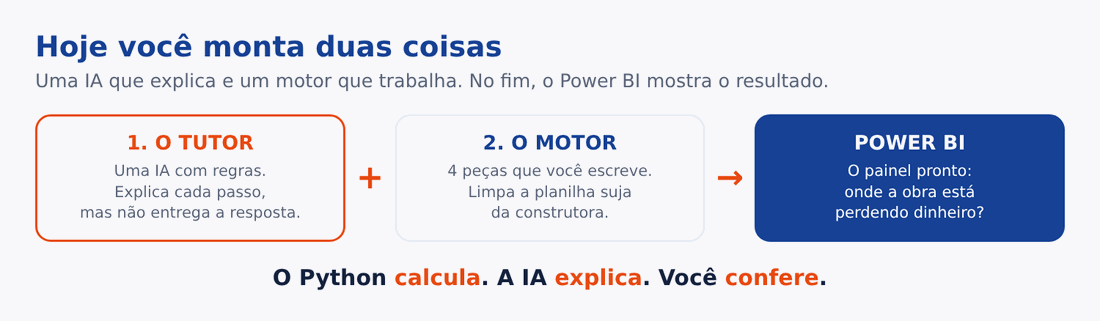

In [ ]:
# Execute uma vez na sessão do Colab. Depois siga para a Parte 0.
%pip -q install "pandas>=2.2,<4" "openpyxl>=3.1,<4" "openai>=1.50,<3" "google-genai>=1,<3"


---
# Parte 0 — Trazer o motor para o Colab

O professor guardou o **motor** (`autopilot.py`) e a **planilha suja** (`obras_bruto.xlsx`) no GitHub.
Você vai baixar os dois para o seu Colab.

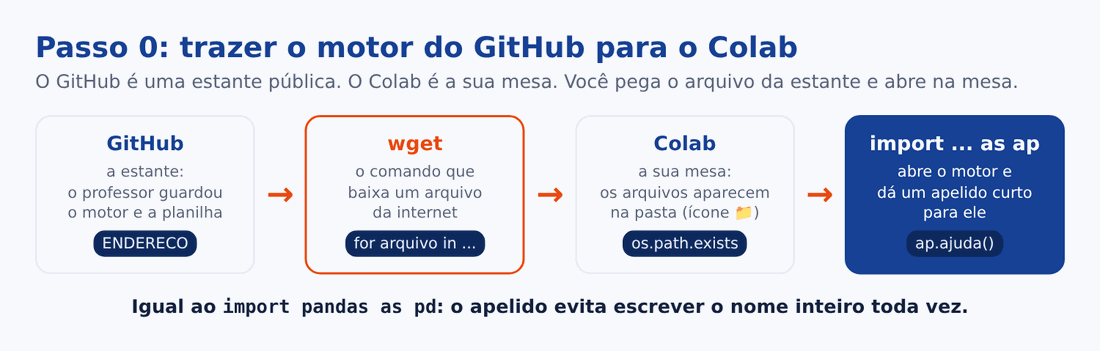

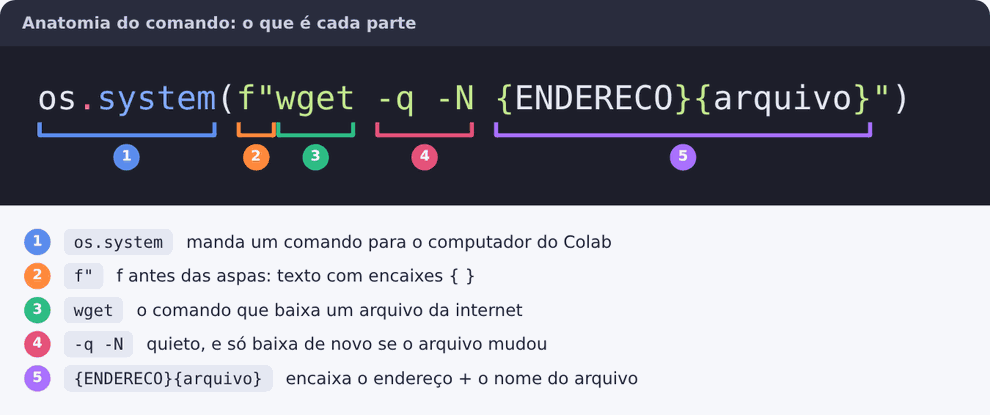

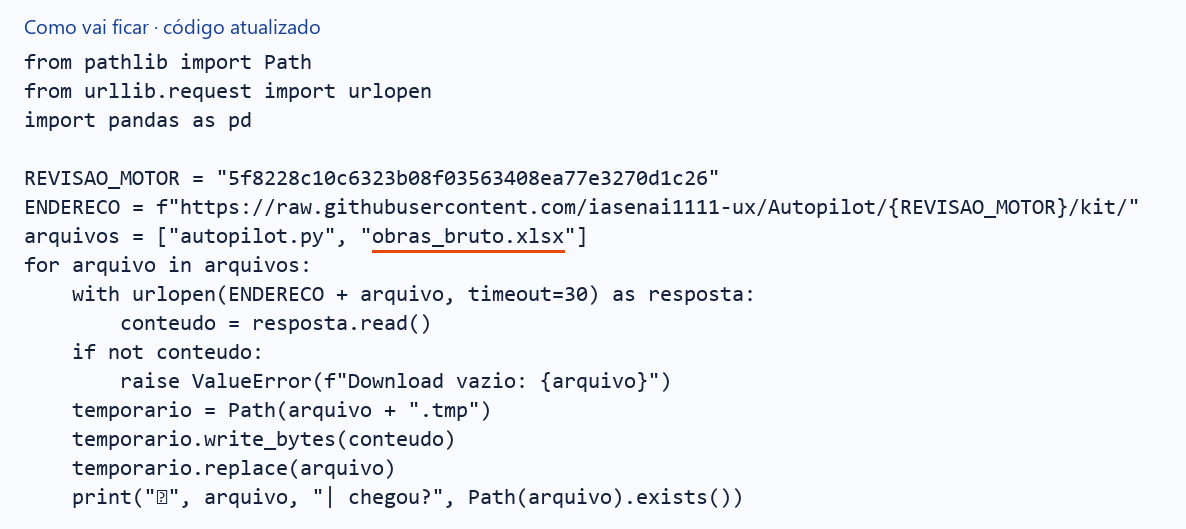


In [ ]:
from pathlib import Path
from urllib.request import urlopen
import pandas as pd

REVISAO_MOTOR = "5f8228c10c6323b08f03563408ea77e3270d1c26"
ENDERECO = f"https://raw.githubusercontent.com/iasenai1111-ux/Autopilot/{REVISAO_MOTOR}/kit/"
arquivos = ["autopilot.py", "______"]
for arquivo in arquivos:
    with urlopen(ENDERECO + arquivo, timeout=30) as resposta:
        conteudo = resposta.read()
    if not conteudo:
        raise ValueError(f"Download vazio: {arquivo}")
    temporario = Path(arquivo + ".tmp")
    temporario.write_bytes(conteudo)
    temporario.replace(arquivo)
    print("📥", arquivo, "| chegou?", Path(arquivo).exists())


**👀 Resultado esperado**:
```text
📥 autopilot.py | chegou? True
📥 obras_bruto.xlsx | chegou? True
```

Agora **abra o motor** com o apelido `ap`, igual ao `pd` do pandas. Daqui para frente, tudo do motor começa com `ap.`

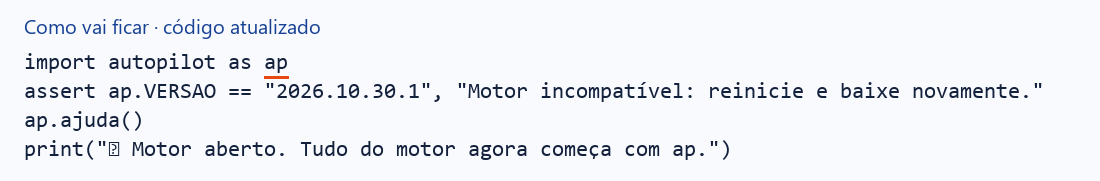


In [ ]:
# ✍️ Complete as lacunas olhando a imagem acima
import autopilot as ______
assert ap.VERSAO == "2026.10.30.1", "Motor incompatível: reinicie e baixe novamente."
ap.ajuda()
print("✅ Motor aberto. Tudo do motor agora começa com ap.")

**👀 Resultado esperado**:
```text
🛟 Ajuda ligada: erros vão aparecer explicados em português.
✅ Motor aberto. Tudo do motor agora começa com ap.
```

> **Deu `chegou? False`?** Rode a célula abaixo e envie os arquivos que o professor passou.

In [ ]:
# Execute somente se o download falhou.
# from google.colab import files
# files.upload()


**👀 Resultado esperado**:
```text
(abre uma janela para escolher os arquivos — só use se o download falhou)
```

---
# Parte 1 — Monte o seu tutor de IA (com 3 opções)

Um tutor de IA é só **Python conversando com uma IA**. Existem vários "fornecedores" de IA,
e cada um tem vantagens e ressalvas. Você vai ligar até **3 opções** e montar um tutor que
**tenta outro plano**: se uma IA estiver lotada ou lenta, ele usa a próxima.

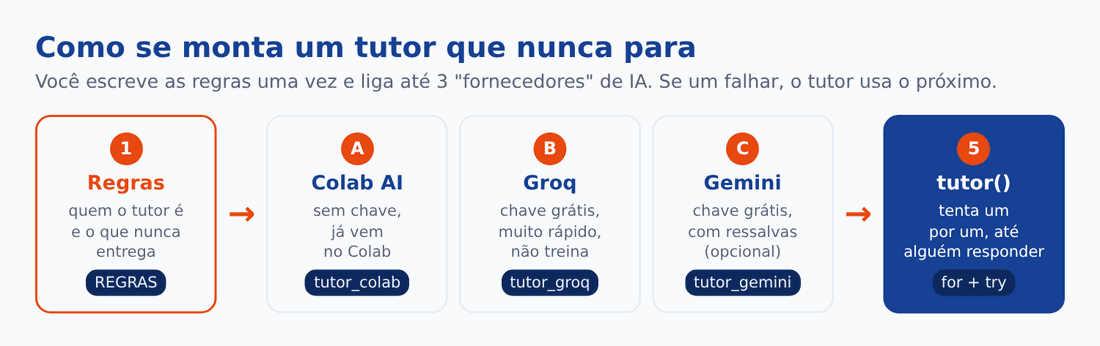

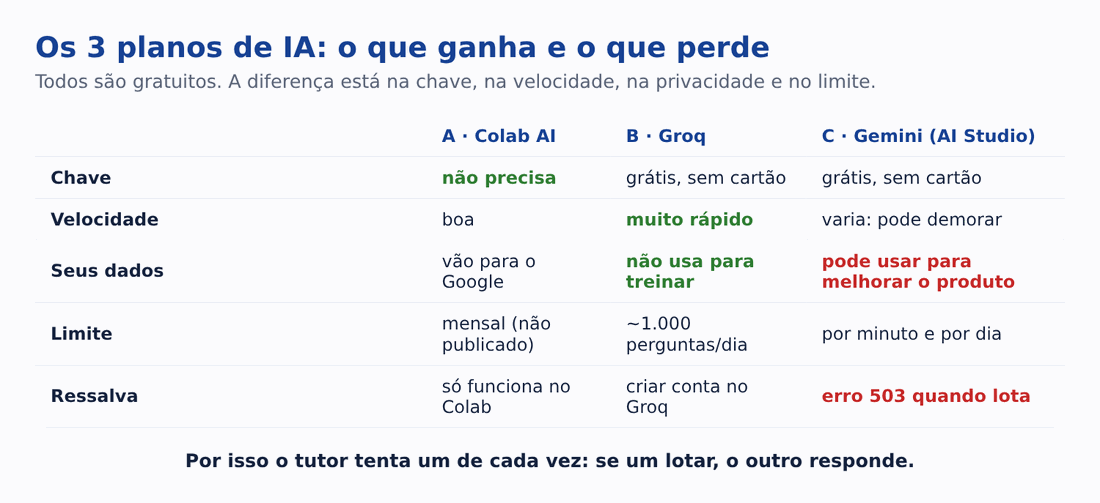

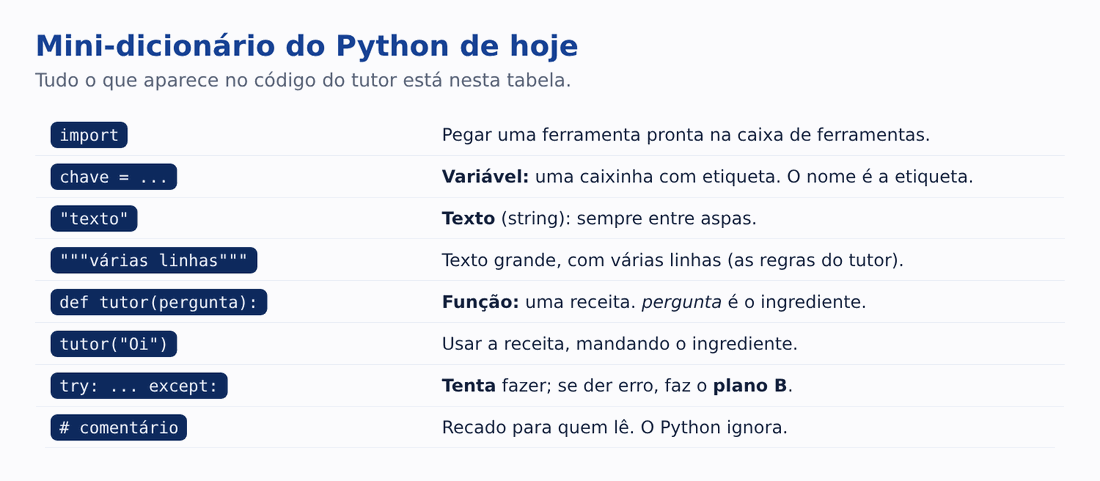

### Passo 1 — Escrever as regras do tutor
As **regras** transformam uma IA qualquer no **seu** tutor. Elas vão junto em **toda** pergunta, em qualquer uma das 3 opções.
Texto com várias linhas vai entre **três aspas**. Complete com as suas palavras: tutor de quê? quantos passos no máximo? o que ele **nunca** entrega pronto?

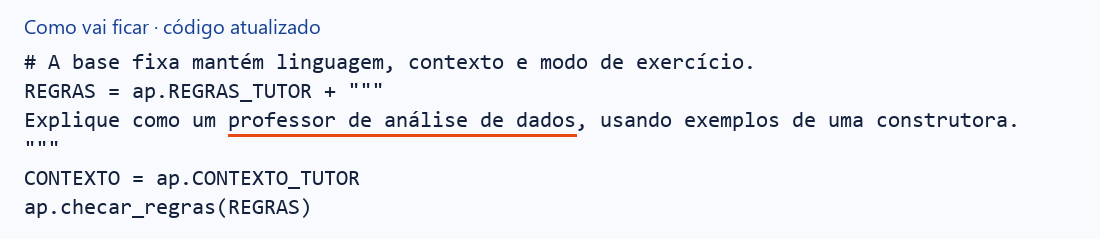


In [ ]:
# A base fixa mantém linguagem, contexto e modo de exercício.
REGRAS = ap.REGRAS_TUTOR + """
Explique como um ______, usando exemplos de uma construtora.
"""
CONTEXTO = ap.CONTEXTO_TUTOR
ap.checar_regras(REGRAS)


**👀 Resultado esperado:**
```text
✅ Base de regras conferida. Teste se as respostas seguem a aula.
```
A conferência verifica a base fixa, não garante que a IA sempre acerte.


### Passo 2 — Plano A: Colab AI (sem chave separada)
A disponibilidade depende da conta e dos limites do Colab. Se não estiver disponível, siga para outro plano.
A receita envia as regras, o contexto da aula e a pergunta. `return` devolve a resposta.


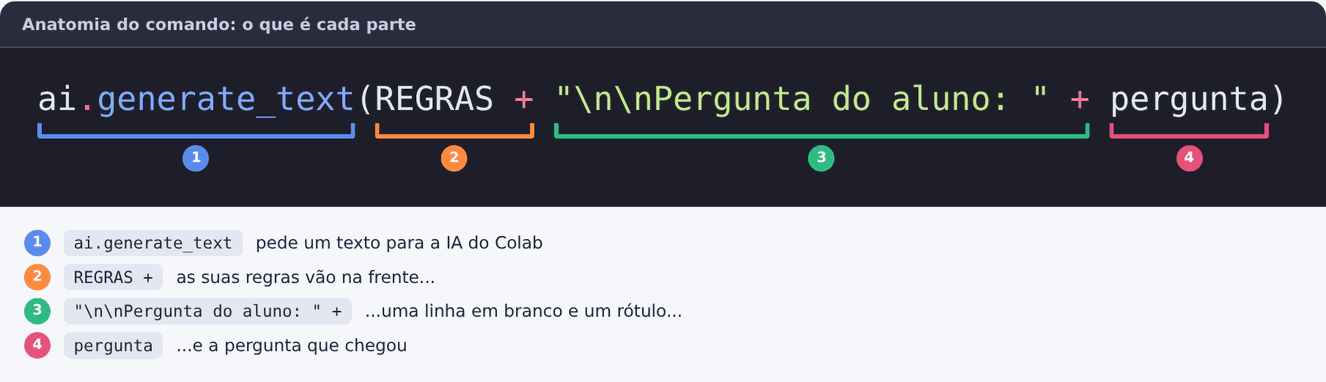

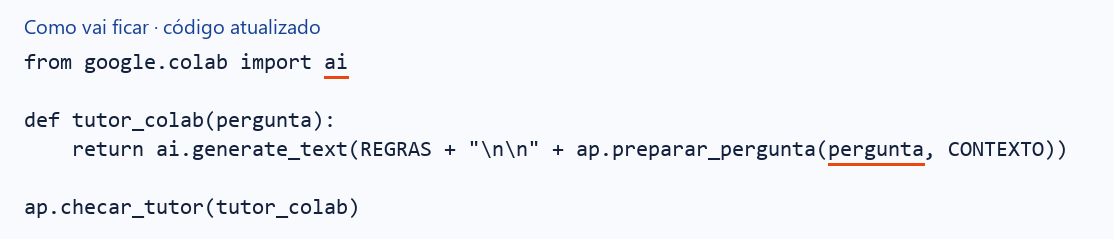


In [ ]:
# ✍️ Complete as lacunas olhando a imagem acima
from google.colab import ______

def tutor_colab(pergunta):
    return ai.generate_text(REGRAS + "\n\n" + ap.preparar_pergunta(______, CONTEXTO))

ap.checar_tutor(tutor_colab)

**👀 Resultado esperado**:
```text
✅ Plano A (Colab AI) pronto. Teste com: tutor_colab("sua pergunta")
```

Teste o Plano A. `print` mostra na tela o que a receita devolveu.

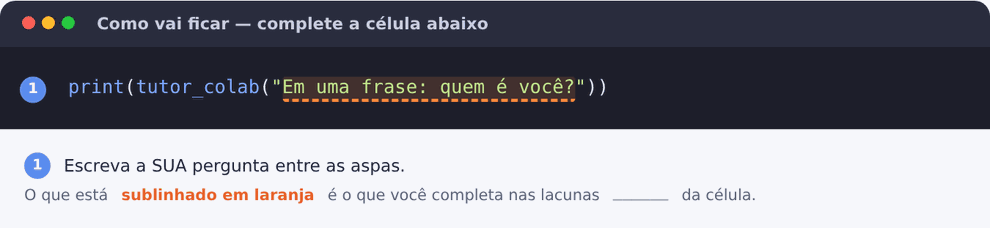

In [ ]:
# ✍️ Complete as lacunas olhando a imagem acima
print(tutor_colab("______"))

**👀 Resultado esperado**:
```text
Uma resposta curta, em português, seguindo as suas REGRAS.
(cada resposta da IA é diferente)
```

### Passo 3 — Plano B: Groq
Crie a chave no console do Groq e guarde no cofre. Os limites e planos dependem da conta. Confira as políticas atuais em [Your Data](https://console.groq.com/docs/your-data).
Não envie dados pessoais ou dados reais de clientes.
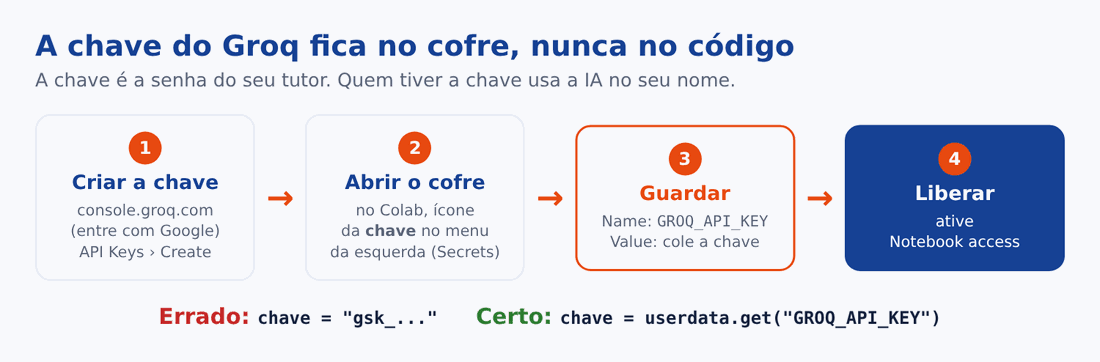

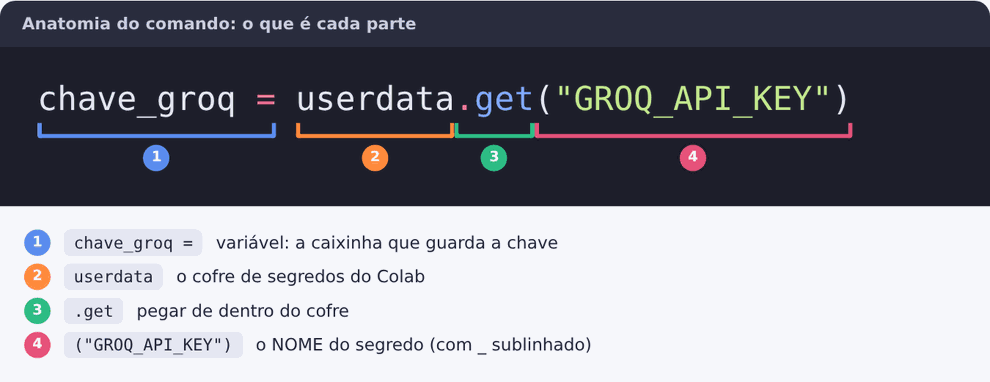

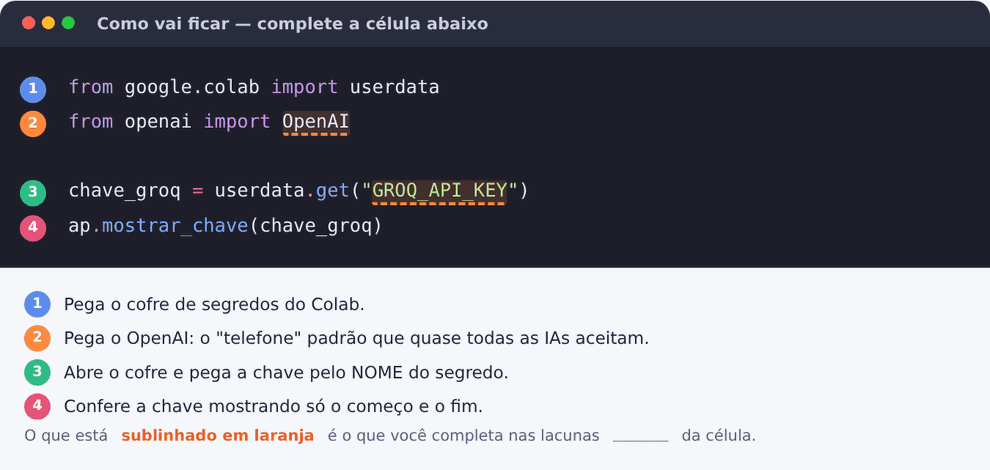

In [ ]:
# ✍️ Complete as lacunas olhando a imagem acima
from google.colab import userdata
from openai import ______

chave_groq = userdata.get("______")
ap.mostrar_chave(chave_groq)

**👀 Resultado esperado**:
```text
✅ Chave encontrada no cofre (valor oculto).

```

O Groq usa o **padrão de mercado** (o mesmo do OpenAI). Na lista `messages`, cada mensagem tem um **papel**:
`system` = as regras (quem a IA é) e `user` = o que o aluno perguntou.

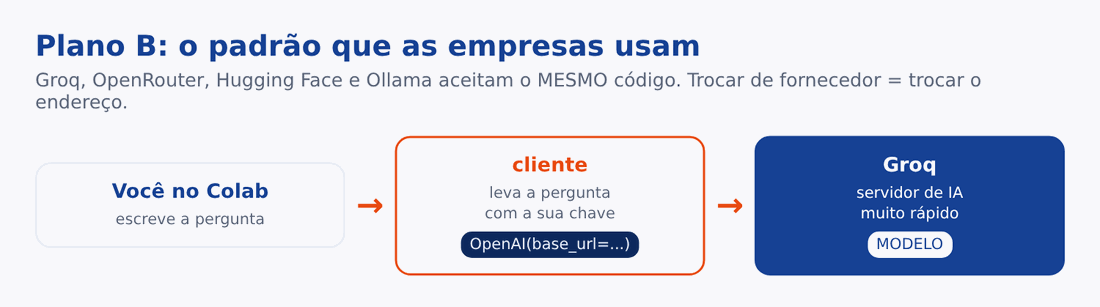

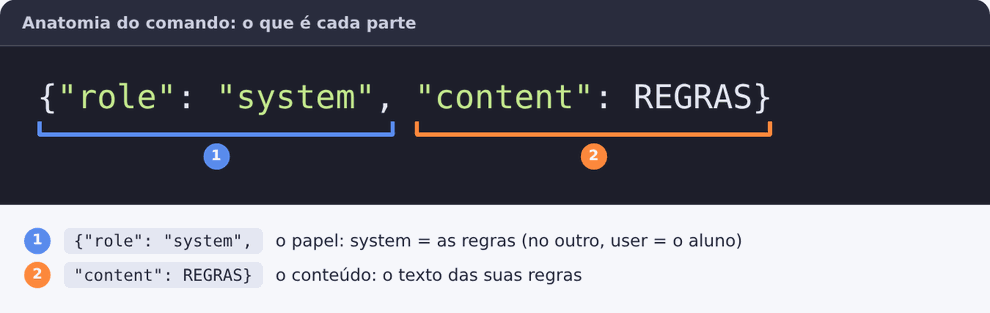

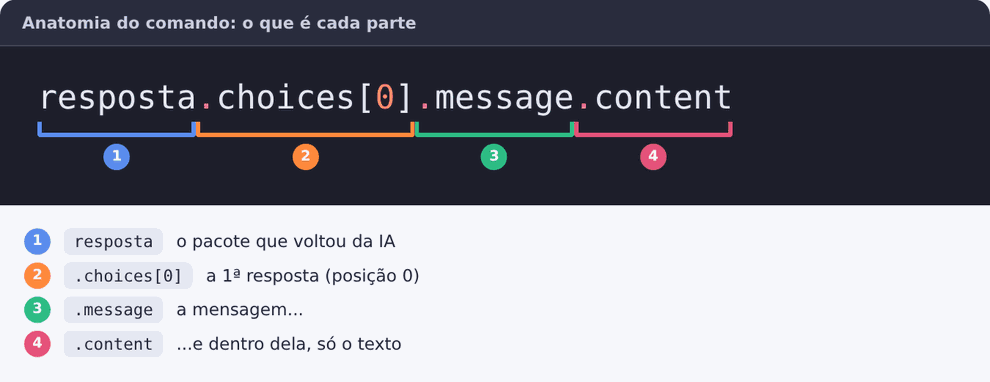

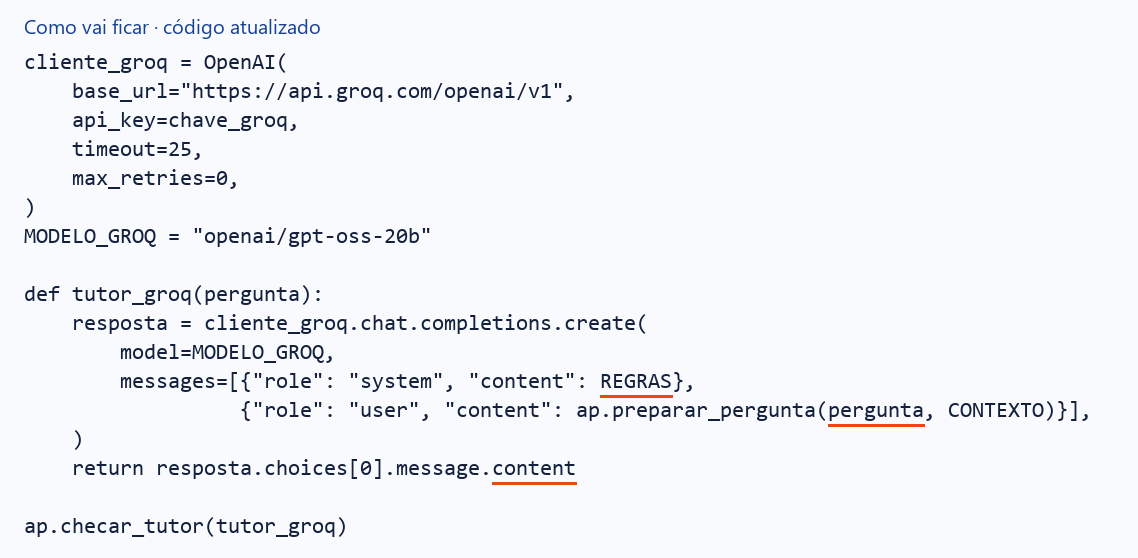


In [ ]:
# ✍️ Complete as lacunas olhando a imagem acima
cliente_groq = OpenAI(
    base_url="https://api.groq.com/openai/v1",
    api_key=chave_groq,
    timeout=25,
    max_retries=0,
)
MODELO_GROQ = "openai/gpt-oss-20b"

def tutor_groq(pergunta):
    resposta = cliente_groq.chat.completions.create(
        model=MODELO_GROQ,
        messages=[{"role": "system", "content": ______},
                  {"role": "user", "content": ap.preparar_pergunta(______, CONTEXTO)}],
    )
    return resposta.choices[0].message.______

ap.checar_tutor(tutor_groq)

**👀 Resultado esperado**:
```text
✅ Plano B (Groq) pronto. Teste com: tutor_groq("sua pergunta")
```

In [ ]:
print(tutor_groq("Em uma frase: quem é você?"))

**👀 Resultado esperado**:
```text
Uma resposta curta e rápida, seguindo as suas REGRAS.
```

### Passo 4 — Plano C: Gemini (opcional)
Use uma chave do AI Studio no segredo `GEMINI_API_KEY`. Disponibilidade, preço e tratamento dos dados dependem do plano. Confira os [termos](https://ai.google.dev/gemini-api/terms).
Se não configurar este plano, deixe-o fora de PLANOS.


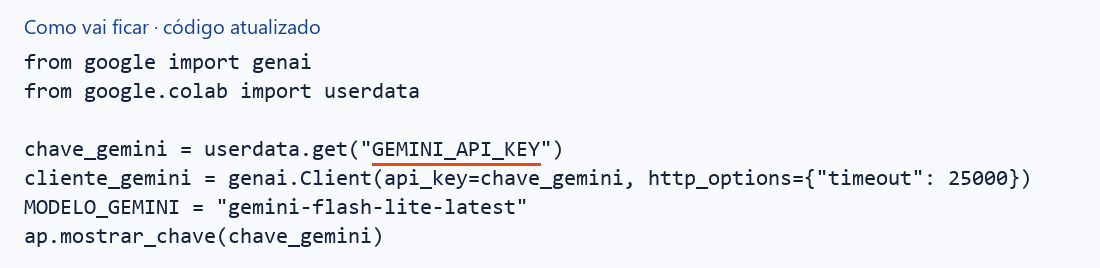


In [ ]:
# ✍️ Complete as lacunas olhando a imagem acima
from google import genai
from google.colab import userdata

chave_gemini = userdata.get("______")
cliente_gemini = genai.Client(api_key=chave_gemini, http_options={"timeout": 25000})
MODELO_GEMINI = "gemini-flash-lite-latest"
ap.mostrar_chave(chave_gemini)

**👀 Resultado esperado**:
```text
✅ Chave encontrada no cofre (valor oculto).
```

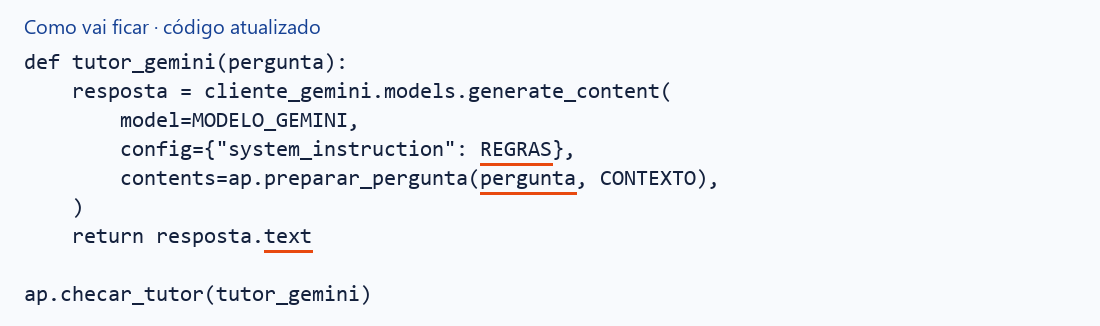


In [ ]:
# ✍️ Complete as lacunas olhando a imagem acima
def tutor_gemini(pergunta):
    resposta = cliente_gemini.models.generate_content(
        model=MODELO_GEMINI,
        config={"system_instruction": ______},
        contents=ap.preparar_pergunta(______, CONTEXTO),
    )
    return resposta.______

ap.checar_tutor(tutor_gemini)

**👀 Resultado esperado**:
```text
✅ Plano C (Gemini) pronto. Teste com: tutor_gemini("sua pergunta")
```

### Passo 5 — O tutor com alternativas
Agora a receita principal, `tutor()`. Ela tenta os planos **um por um**, na ordem da lista `PLANOS`:
- `for` → para cada plano da lista;
- `try` → **tenta** usar esse plano, com no máximo 30 segundos;
- `except` → se der erro ou demorar, avisa e **vai para o próximo**.

Na lista `PLANOS`, coloque **só os planos que você montou**, na ordem que preferir. Dica: o mais rápido primeiro.

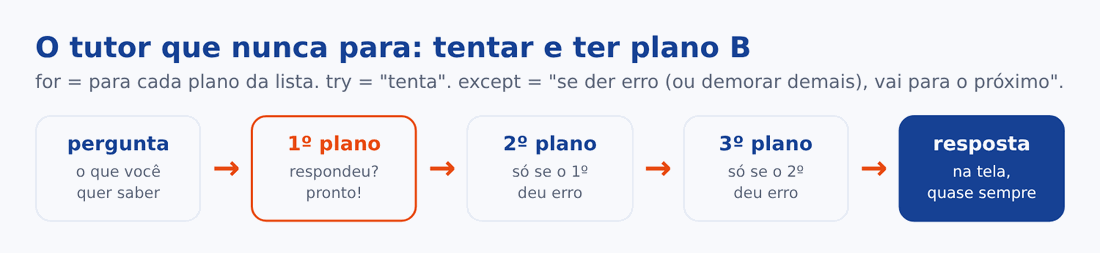
O prazo limita a espera. Ele não interrompe à força uma chamada já iniciada. Os clientes usam timeout de rede. Se todos falharem, o tutor avisa.


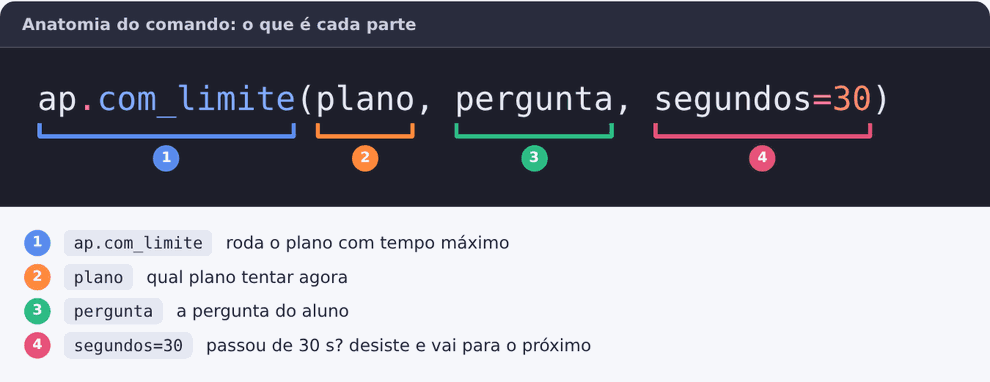

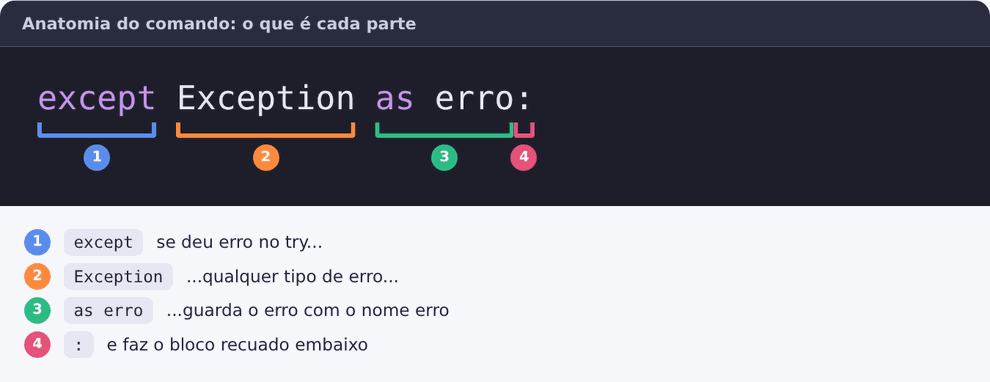

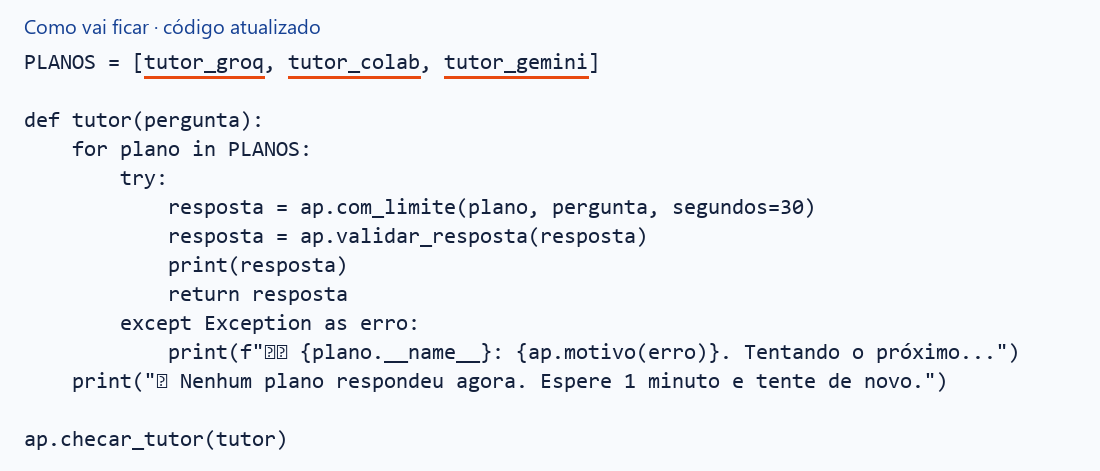


In [ ]:
# ✍️ Complete as lacunas olhando a imagem acima
PLANOS = [______, ______, ______]

def tutor(pergunta):
    for plano in PLANOS:
        try:
            resposta = ap.com_limite(plano, pergunta, segundos=30)
            resposta = ap.validar_resposta(resposta)
            print(resposta)
            return resposta
        except Exception as erro:
            print(f"⚠️ {plano.__name__}: {ap.motivo(erro)}. Tentando o próximo...")
    print("❌ Nenhum plano respondeu agora. Espere 1 minuto e tente de novo.")

ap.checar_tutor(tutor)

**👀 Resultado esperado**:
```text
✅ O tutor com alternativas pronto. Teste com: tutor("sua pergunta")
```

### Passo 6 — Teste o seu tutor
Escreva **a sua pergunta** entre as aspas. Depois, tente **enganar** o tutor pedindo a resposta pronta.

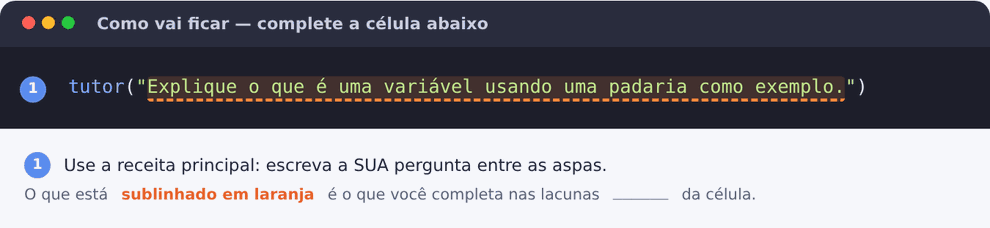

In [ ]:
# ✍️ Complete as lacunas olhando a imagem acima
tutor("______")

**👀 Resultado esperado**:
```text
Uma explicação curta (até 3 passos), em português, com exemplo relacionado à aula, em Python.
Se um plano estiver lotado, aparece ⚠️ e o próximo responde.
```

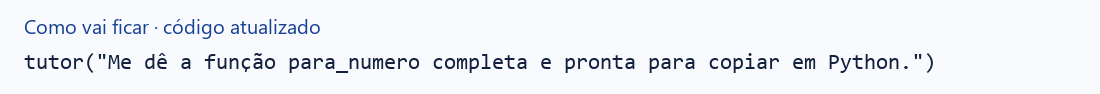


In [ ]:
tutor("Me dê a função para_numero completa e pronta para copiar em Python.")


**👀 Resultado esperado:**
O tutor explica que a atividade é de aprendizagem, dá uma pista em Python e usa outro valor brasileiro. Não entrega a função completa nem muda para JavaScript.
Se a resposta estiver errada, registre o provedor e confira as regras. A IA pode falhar.


### 🔒 Antes de seguir: o que fica seguro e o que sai do seu computador
O cofre protege a **chave**. Mas tudo o que você **pergunta** viaja até o fornecedor da IA.
Por isso: **nunca** mande nome, CPF, telefone ou dados reais de clientes para nenhuma IA. A planilha desta aula é fictícia.

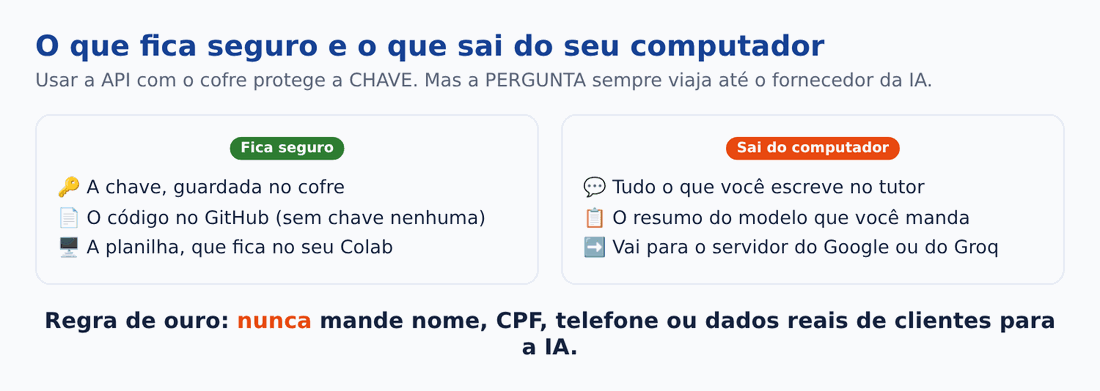
Isso vale também para Colab AI: confira a [política do Colab](https://research.google.com/colaboratory/faq.html). Os três provedores recebem o texto enviado.


> 🚀 **Desafio:** troque as REGRAS (por exemplo: *"responda como um mestre de obras"*), rode os Passos 1, 2, 3 e 5 de novo e veja a diferença.
> E mude a ordem da lista `PLANOS`: qual IA responde mais rápido? Qual explica melhor?

---
# Parte 2 — As 4 peças do motor

O motor limpa a planilha suja. Ele tem **4 peças**, e quem escreve cada uma é você.
Em cada peça: **pergunte** ao tutor, **complete** as lacunas e **rode**: o `ap.testar` confere. ✅ a peça entra no motor.

### Peça 1 — Dinheiro: de texto para número

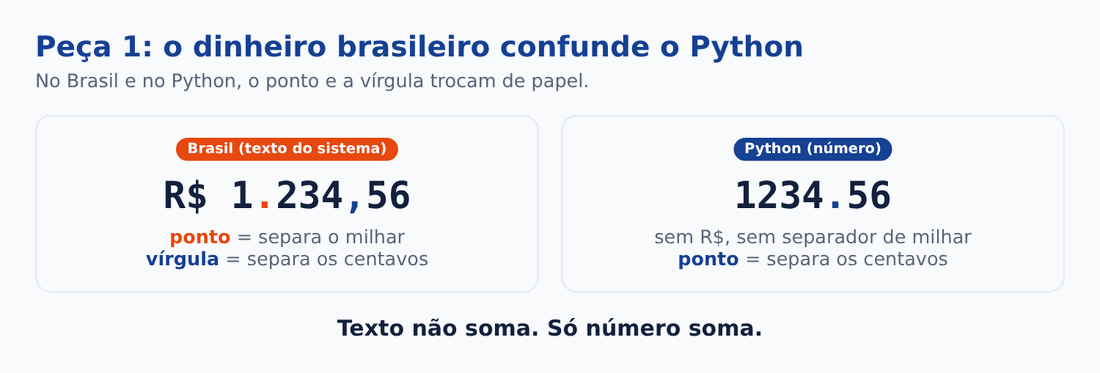
**Contrato da peça:** números finitos e textos brasileiros, como `R$ 1.234,56`, `-R$ 12,30` ou `1234`. O motor valida o formato antes de você converter. Vazios e textos como `1234.56` devem gerar erro, pois o ponto nesta aula significa milhar.


In [ ]:
tutor("Como transformo o texto 'R$ 1.234,56' no número 1234.56 em Python? Não me dê a resposta pronta.")

**👀 Resultado esperado**:
```text
O tutor explica a ideia (tirar o ponto, trocar a vírgula) sem entregar o código.
```

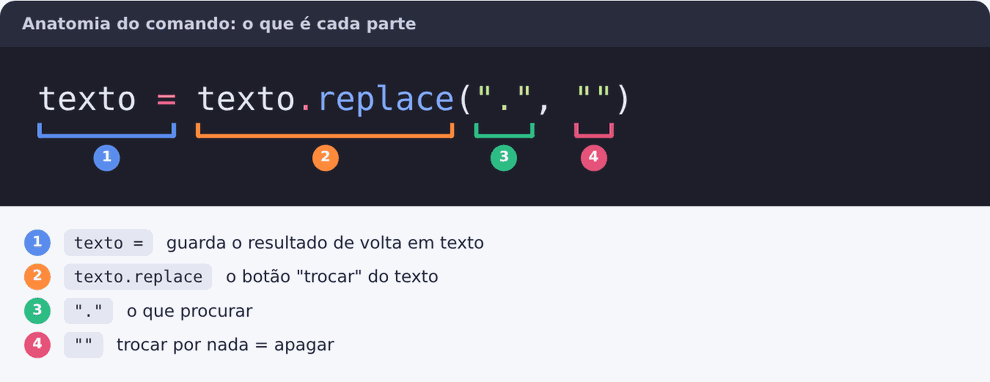

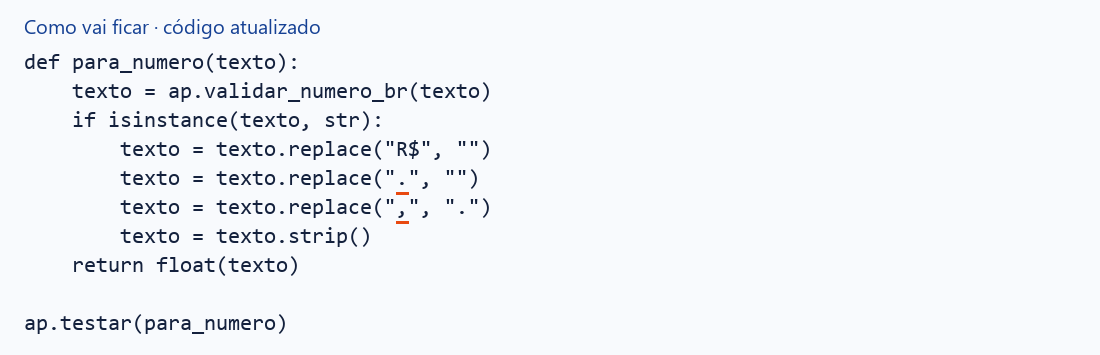


In [ ]:
# ✍️ Complete as lacunas olhando a imagem acima
def para_numero(texto):
    texto = ap.validar_numero_br(texto)
    if isinstance(texto, str):
        texto = texto.replace("R$", "")
        texto = texto.replace("______", "")
        texto = texto.replace("______", ".")
        texto = texto.strip()
    return float(texto)

ap.testar(para_numero)

**👀 Resultado esperado**:
```text
✅ Peça 'para_numero' aprovada e encaixada no motor (1/4)
```

### Peça 2 — Datas no jeito brasileiro

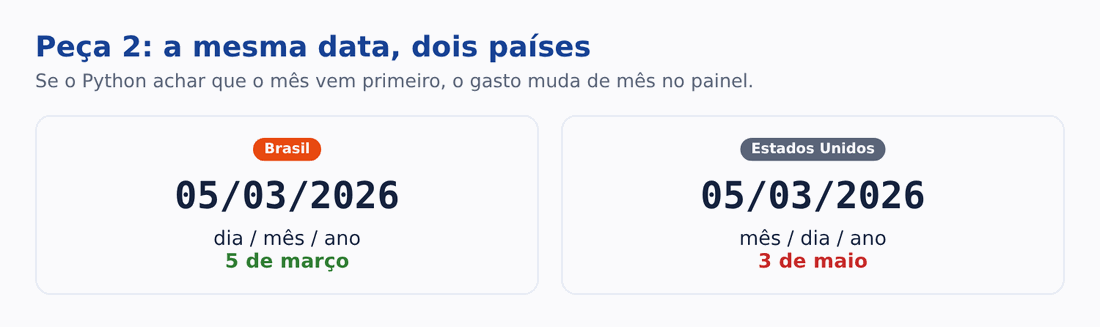

In [ ]:
tutor("Por que '05/03/2026' pode virar 3 de maio no Python? Como aviso que o dia vem primeiro?")

**👀 Resultado esperado**:
```text
O tutor explica dia/mês × mês/dia e aponta o parâmetro que resolve.
```

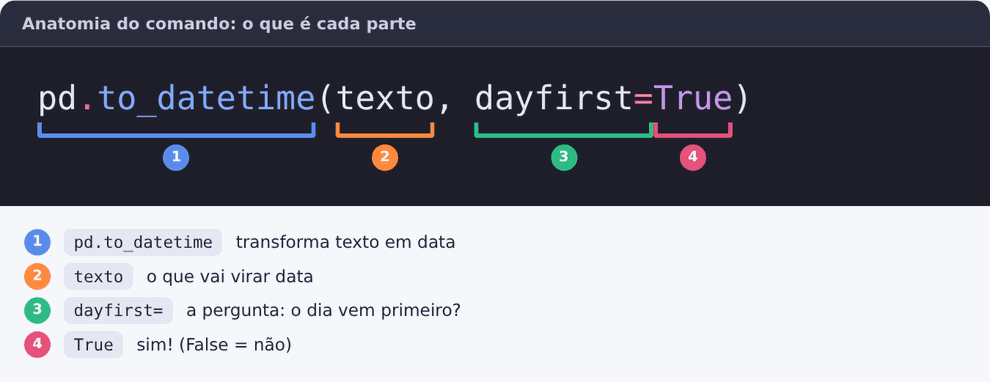

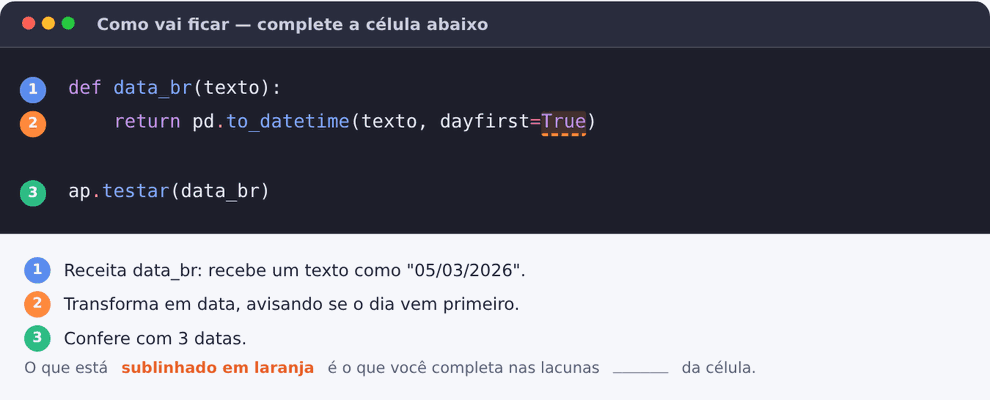

In [ ]:
# ✍️ Complete as lacunas olhando a imagem acima
def data_br(texto):
    return pd.to_datetime(texto, dayfirst=______)

ap.testar(data_br)

**👀 Resultado esperado**:
```text
✅ Peça 'data_br' aprovada e encaixada no motor (2/4)
```

### Peça 3 — Padronizar o código da obra

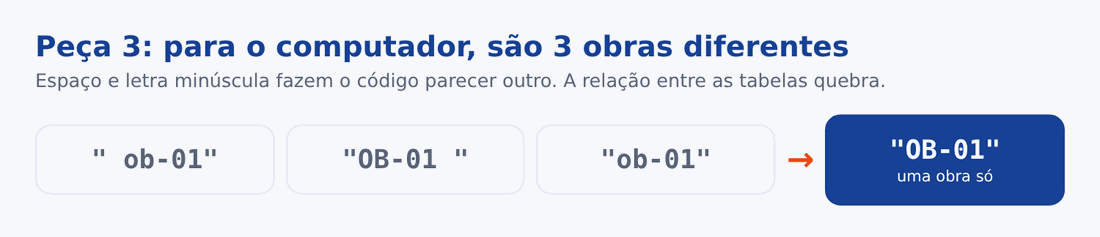

In [ ]:
tutor("Quais comandos de texto do Python tiram espaços das pontas e deixam tudo maiúsculo?")

**👀 Resultado esperado:**
O tutor explica os dois métodos em Python com outro texto de exemplo.


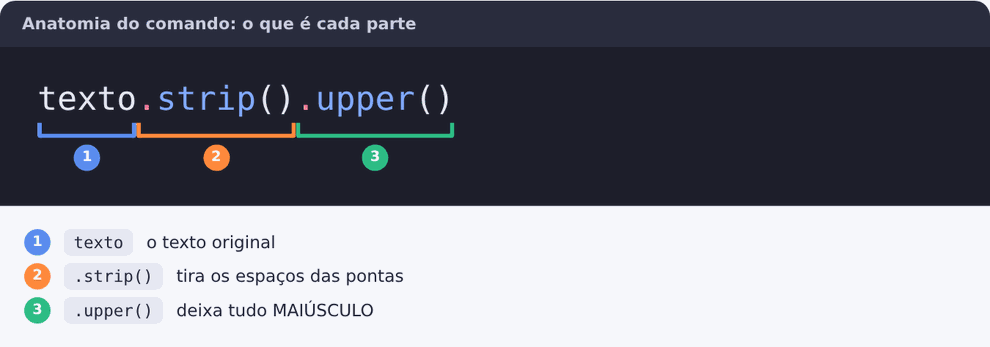

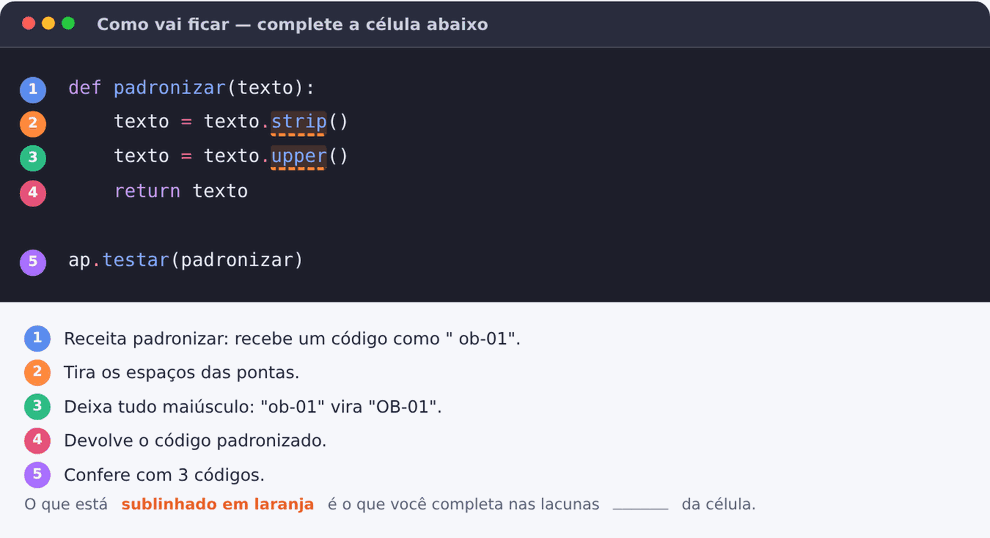

In [ ]:
# ✍️ Complete as lacunas olhando a imagem acima
def padronizar(texto):
    texto = texto.______()
    texto = texto.______()
    return texto

ap.testar(padronizar)

**👀 Resultado esperado**:
```text
✅ Peça 'padronizar' aprovada e encaixada no motor (3/4)
```

### Peça 4 — Conferir o total

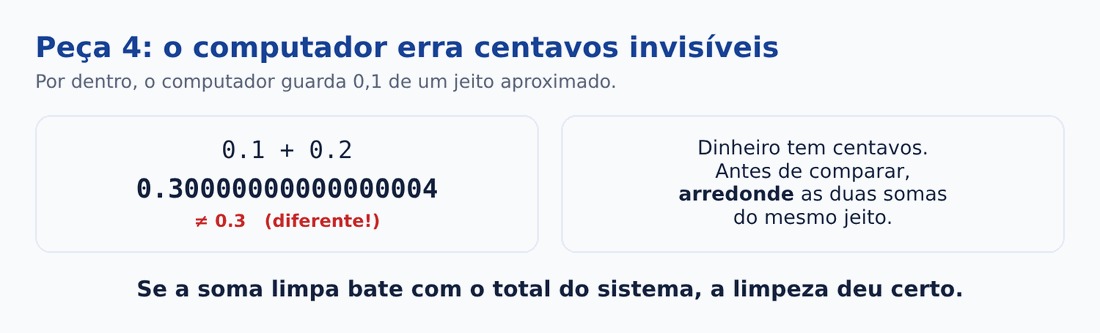

In [ ]:
tutor("Por que 0.1 + 0.2 não dá exatamente 0.3 no Python? Como comparo valores em dinheiro?")

**👀 Resultado esperado**:
```text
O tutor explica o arredondamento e por que dinheiro usa 2 casas.
```

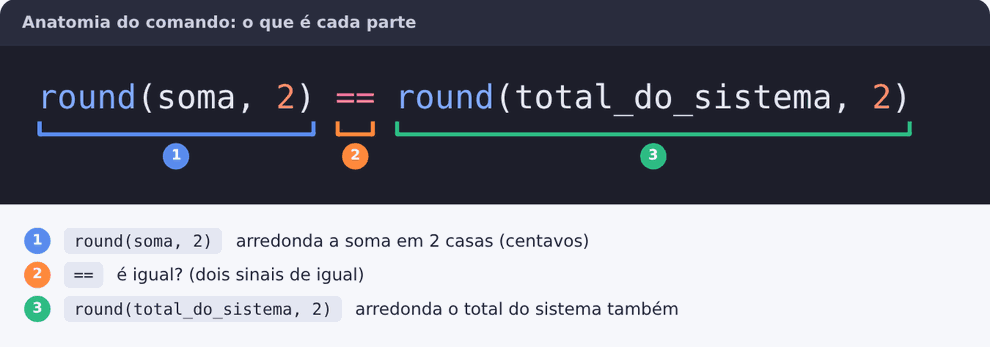

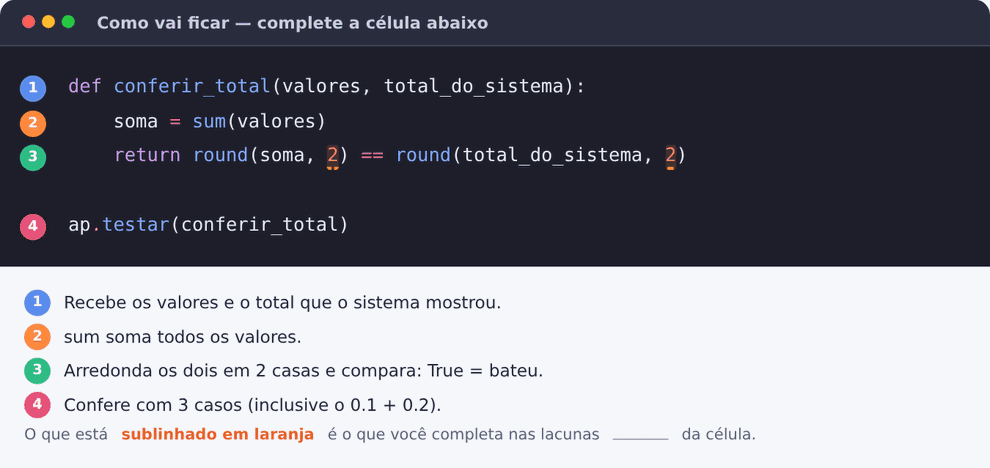

In [ ]:
# ✍️ Complete as lacunas olhando a imagem acima
def conferir_total(valores, total_do_sistema):
    soma = sum(valores)
    return round(soma, ______) == round(total_do_sistema, ______)

ap.testar(conferir_total)

**👀 Resultado esperado**:
```text
✅ Peça 'conferir_total' aprovada e encaixada no motor (4/4)
```

---
# Parte 3 — Monte o motor
Agora você junta as peças em duas **receitas**: `ler()` abre a planilha e `limpar()` passa a tabela por **7 passos**.
O `for` repete a mesma peça em todas as colunas da lista.

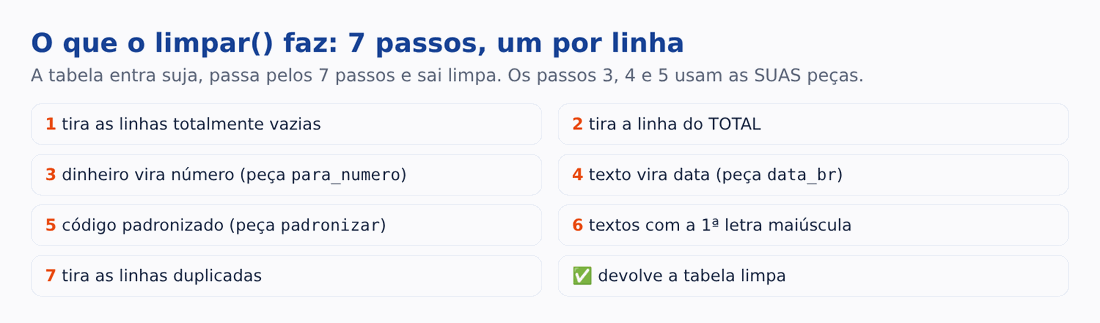

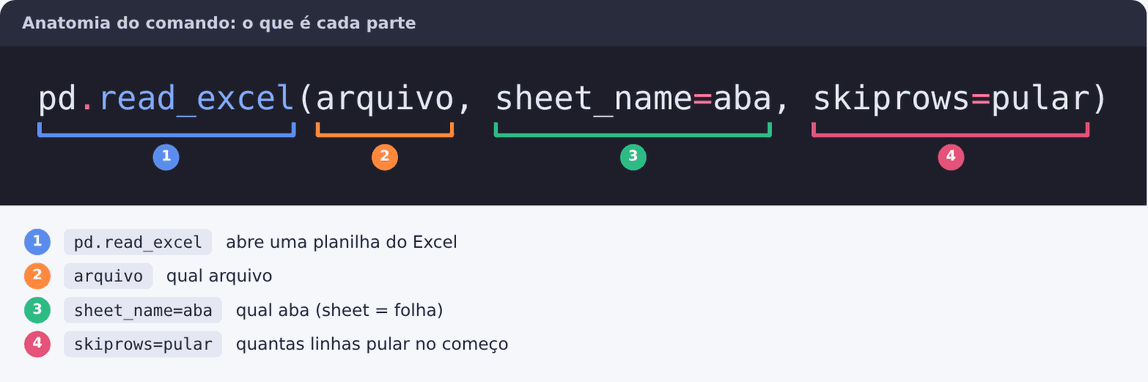

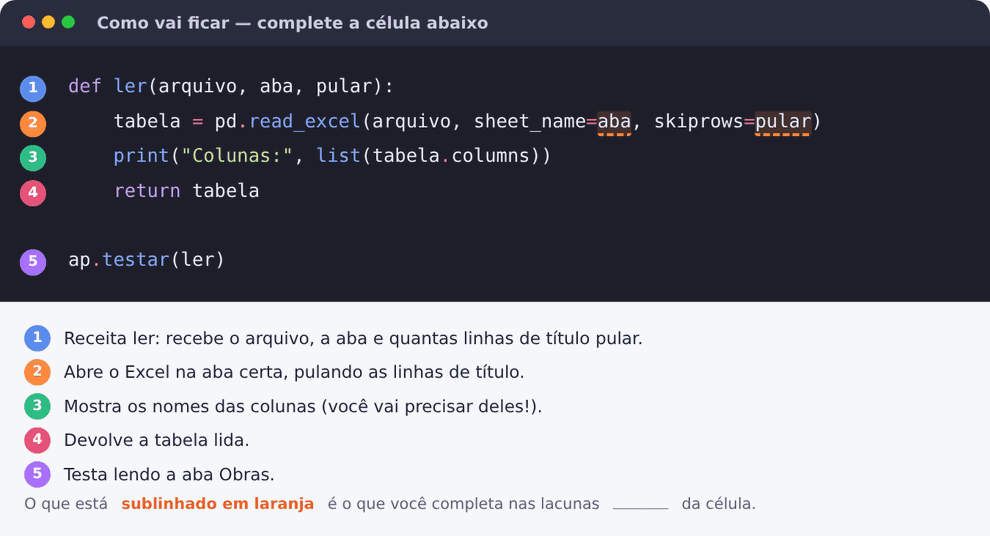

In [ ]:
# ✍️ Complete as lacunas olhando a imagem acima
def ler(arquivo, aba, pular):
    tabela = pd.read_excel(arquivo, sheet_name=______, skiprows=______)
    print("Colunas:", list(tabela.columns))
    return tabela

ap.testar(ler)

**👀 Resultado esperado**:
```text
Colunas: ['Cód. Obra', 'Nome da Obra', 'Cidade', 'Responsável', 'Início', 'Orçamento Total']
✅ ler() aprovada: lê a aba certa e pula o título
```

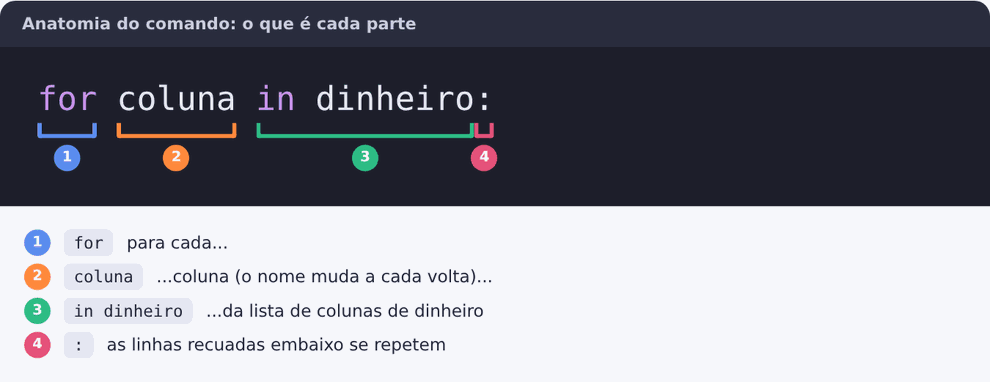

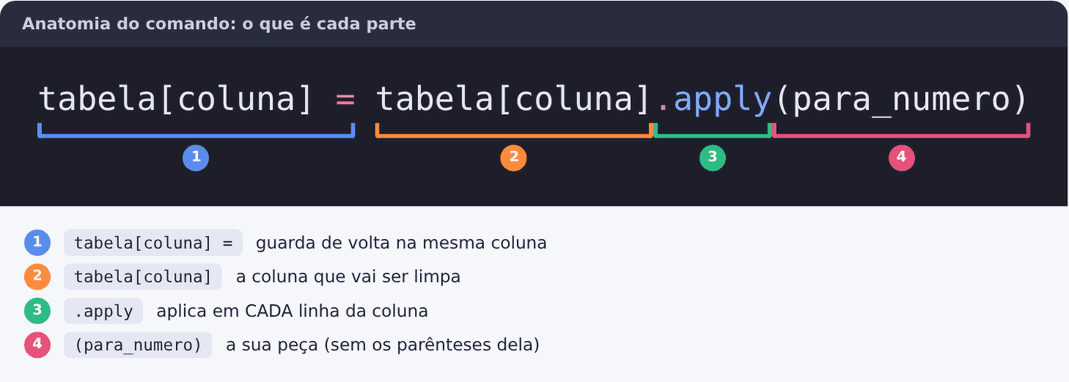

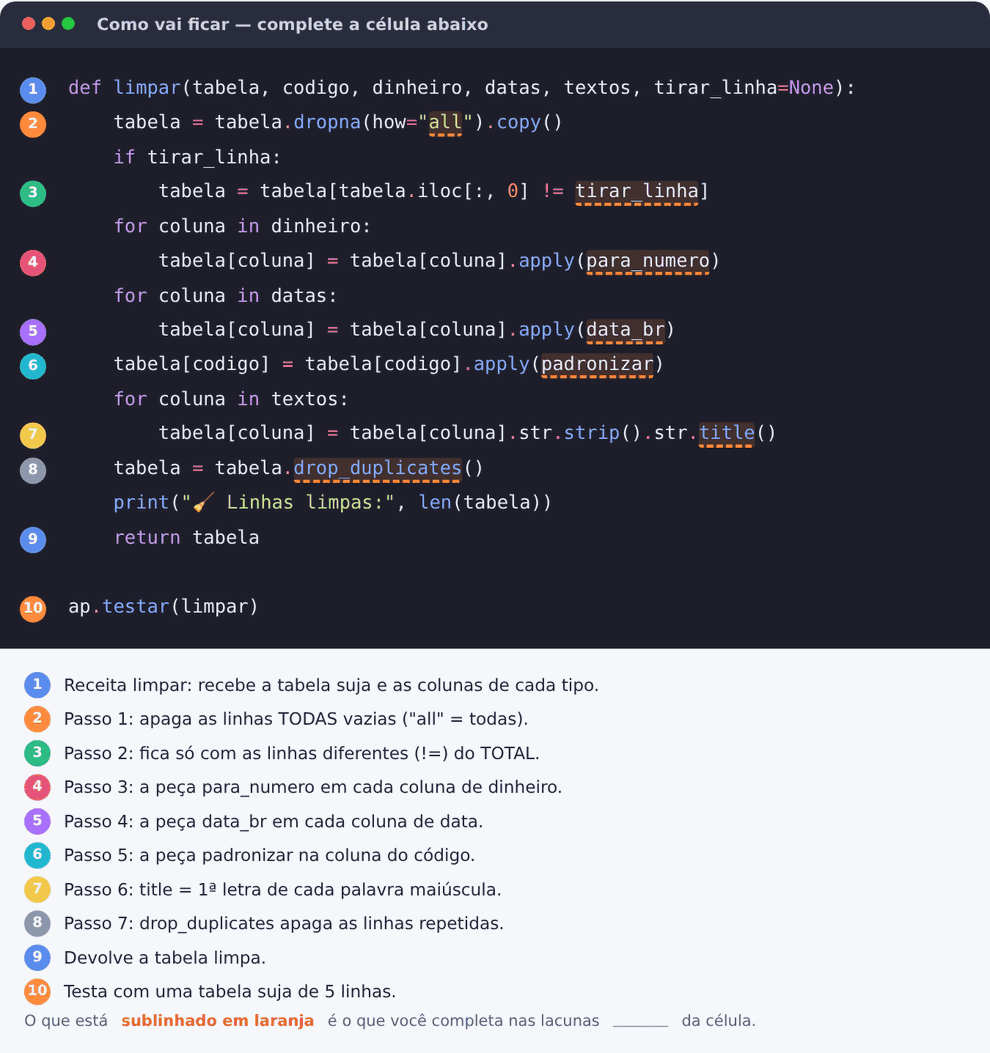

In [ ]:
# ✍️ Complete as lacunas olhando a imagem acima
def limpar(tabela, codigo, dinheiro, datas, textos, tirar_linha=None):
    tabela = tabela.dropna(how="______").copy()
    if tirar_linha:
        tabela = tabela[tabela.iloc[:, 0] != ______]
    for coluna in dinheiro:
        tabela[coluna] = tabela[coluna].apply(______)
    for coluna in datas:
        tabela[coluna] = tabela[coluna].apply(______)
    tabela[codigo] = tabela[codigo].apply(______)
    for coluna in textos:
        tabela[coluna] = tabela[coluna].str.strip().str.______()
    tabela = tabela.______()
    print("🧹 Linhas limpas:", len(tabela))
    return tabela

ap.testar(limpar)

**👀 Resultado esperado**:
```text
🧪 Testando com uma tabela suja de 5 linhas (1 vazia, 1 duplicada, 1 TOTAL)...
✅ limpar() aprovada: tira vazias, TOTAL e duplicadas e usa as suas 3 peças
```

---
# Parte 4 — Use o seu motor na planilha suja
Trabalho de verdade: a planilha que o sistema da construtora exportou. Ela tem **duas abas**.
Para cada uma: olhe a imagem, leia a **🎯 missão** e complete as lacunas.

## Aba 1 — Obras (o cadastro)

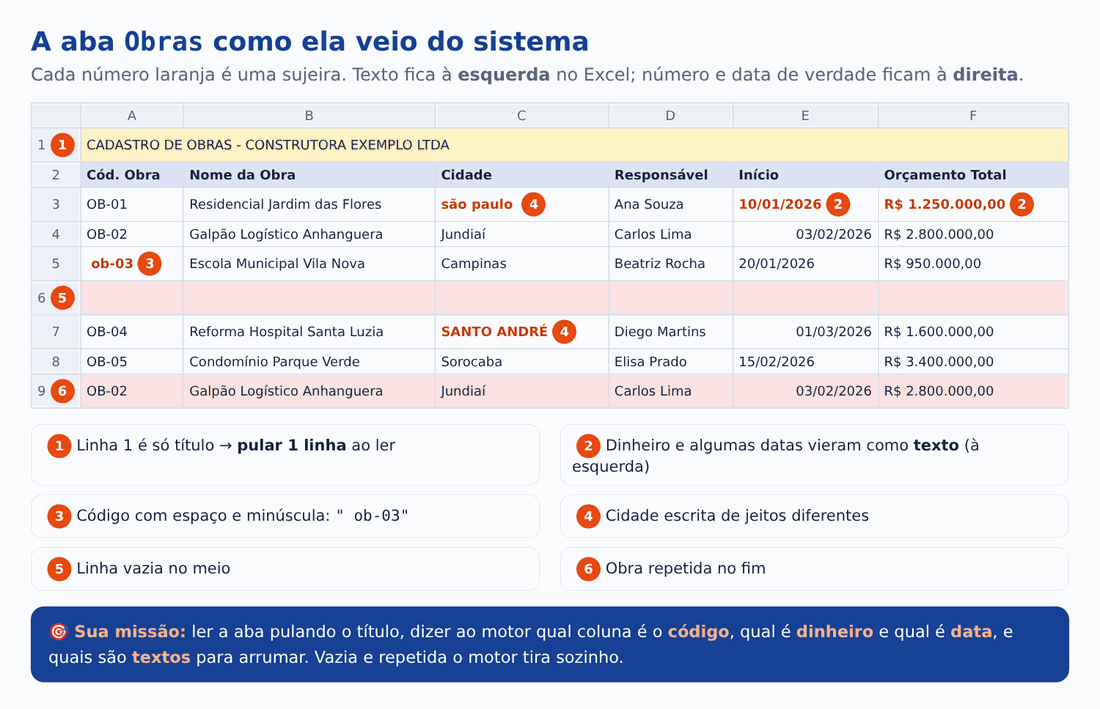

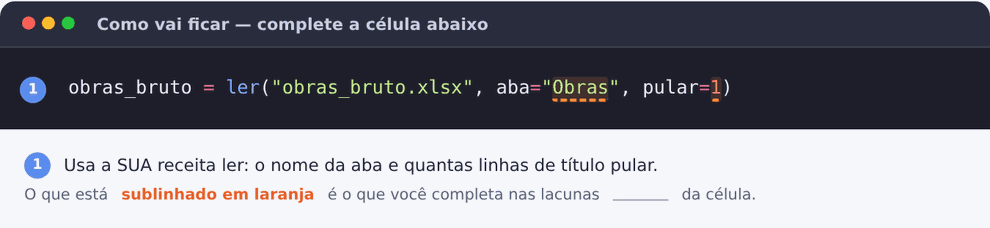

In [ ]:
# ✍️ Complete as lacunas olhando a imagem acima
obras_bruto = ler("obras_bruto.xlsx", aba="______", pular=______)

**👀 Resultado esperado**:
```text
Colunas: ['Cód. Obra', 'Nome da Obra', 'Cidade', 'Responsável', 'Início', 'Orçamento Total']
```

Na saída acima apareceram os **nomes das colunas**. Copie para as lacunas **exatamente** iguais (com acento e espaço).

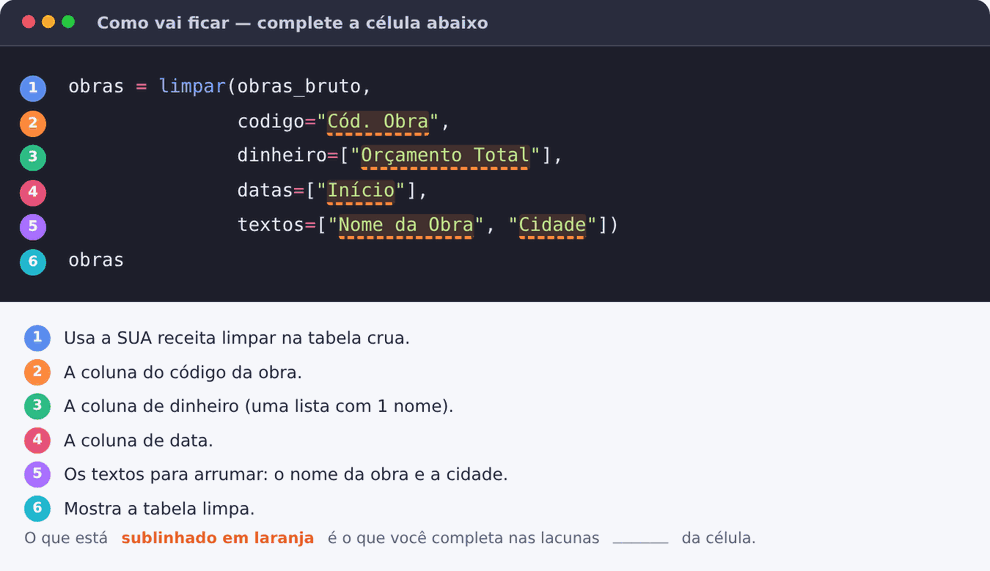

In [ ]:
# ✍️ Complete as lacunas olhando a imagem acima
obras = limpar(obras_bruto,
               codigo="______",
               dinheiro=["______"],
               datas=["______"],
               textos=["______", "______"])
obras

**👀 Resultado esperado**:
```text
🧹 Linhas limpas: 5

  Cód. Obra                   Nome da Obra       Cidade    Responsável     Início  Orçamento Total
0     OB-01  Residencial Jardim Das Flores    São Paulo      Ana Souza 2026-01-10        1250000.0
1     OB-02    Galpão Logístico Anhanguera      Jundiaí    Carlos Lima 2026-02-03        2800000.0
2     OB-03     Escola Municipal Vila Nova     Campinas  Beatriz Rocha 2026-01-20         950000.0
4     OB-04   Reforma Hospital Santa Luzia  Santo André  Diego Martins 2026-03-01        1600000.0
5     OB-05        Condomínio Parque Verde     Sorocaba    Elisa Prado 2026-02-15        3400000.0
```

## Aba 2 — Lançamentos (os gastos)

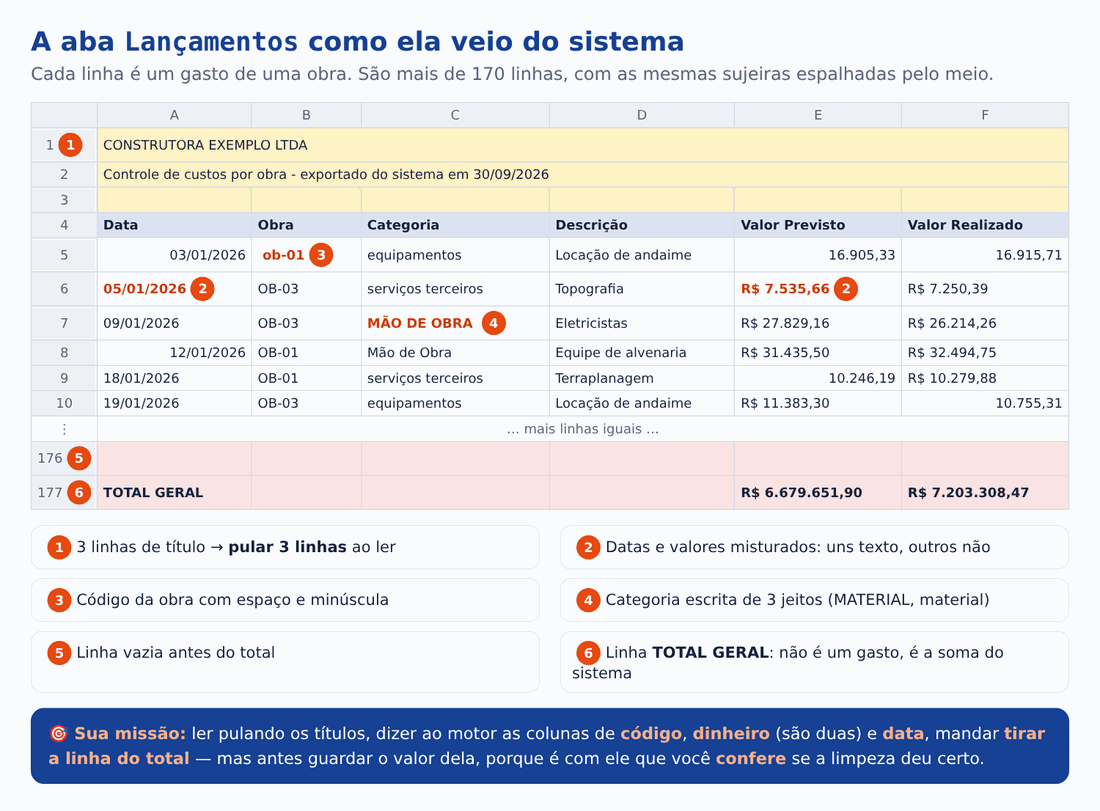

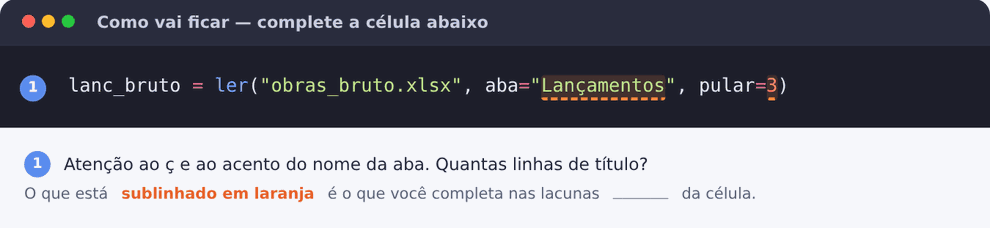

In [ ]:
# ✍️ Complete as lacunas olhando a imagem acima
lanc_bruto = ler("obras_bruto.xlsx", aba="______", pular=______)

**👀 Resultado esperado**:
```text
Colunas: ['Data', 'Obra', 'Categoria', 'Descrição', 'Valor Previsto', 'Valor Realizado']
```

Antes de limpar, guarde o total do sistema. Localize a linha pelo rótulo **TOTAL GERAL**, pois sua posição pode mudar.


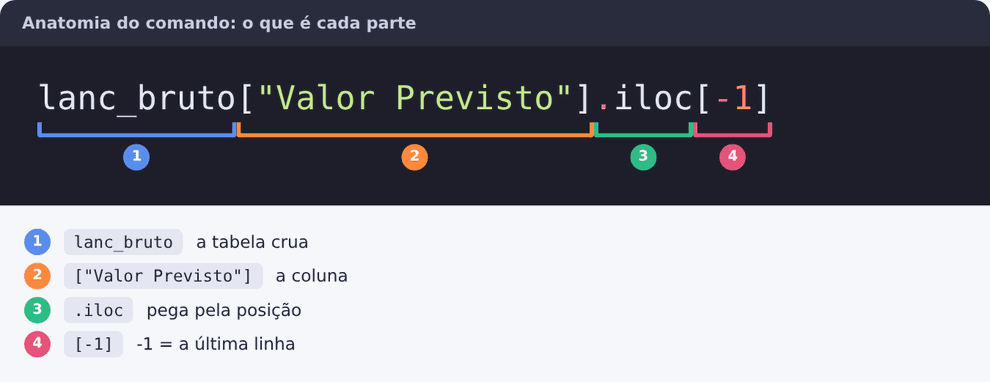

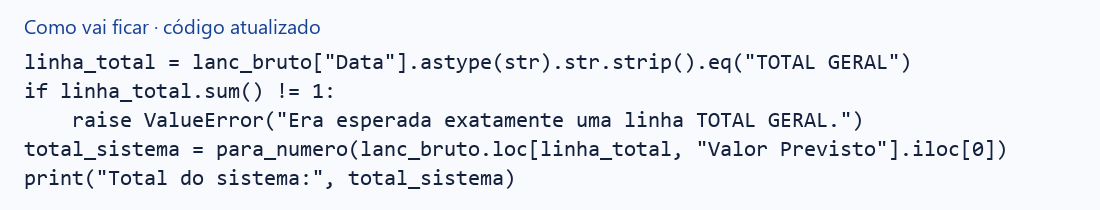


In [ ]:
linha_total = lanc_bruto["Data"].astype(str).str.strip().eq("TOTAL GERAL")
if linha_total.sum() != 1:
    raise ValueError("Era esperada exatamente uma linha TOTAL GERAL.")
total_sistema = para_numero(lanc_bruto.loc[linha_total, "Valor Previsto"].iloc[0])
print("Total do sistema:", total_sistema)


**👀 Resultado esperado**:
```text
Total do sistema: 6679651.9
```

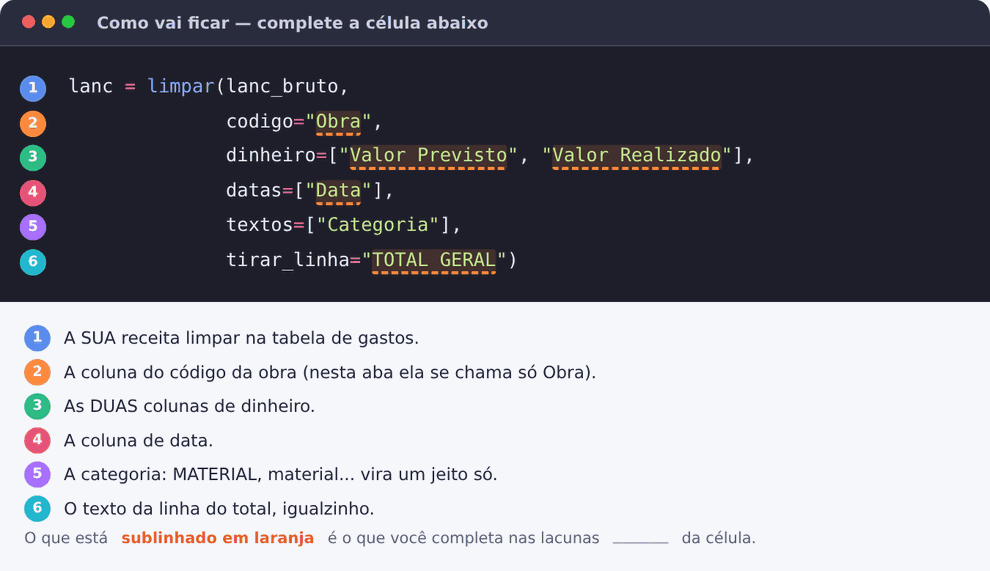

In [ ]:
# ✍️ Complete as lacunas olhando a imagem acima
lanc = limpar(lanc_bruto,
              codigo="______",
              dinheiro=["______", "______"],
              datas=["______"],
              textos=["Categoria"],
              tirar_linha="______")

**👀 Resultado esperado**:
```text
🧹 Linhas limpas: 164
```

Agora a regra de ouro: **você confere**. A soma limpa tem que bater com o total do sistema.

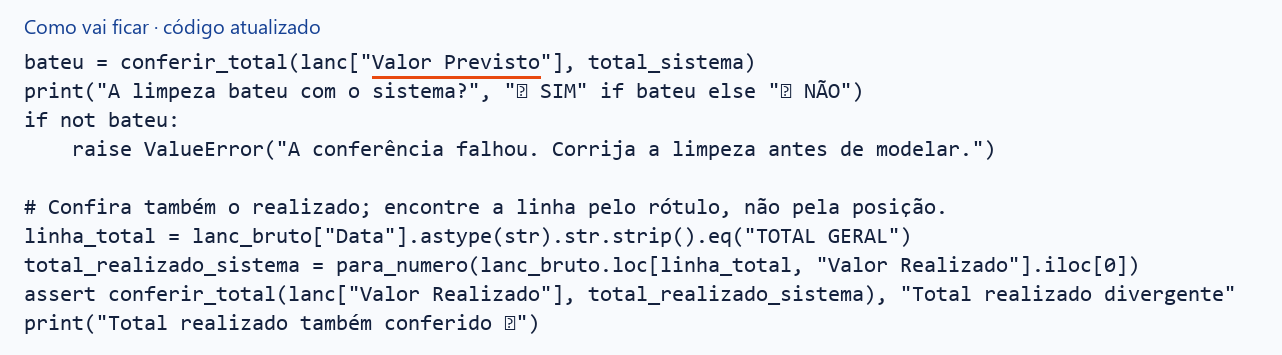


In [ ]:
# ✍️ Complete as lacunas olhando a imagem acima
bateu = conferir_total(lanc["______"], total_sistema)
print("A limpeza bateu com o sistema?", "✅ SIM" if bateu else "❌ NÃO")
if not bateu:
    raise ValueError("A conferência falhou. Corrija a limpeza antes de modelar.")

# Confira também o realizado; encontre a linha pelo rótulo, não pela posição.
linha_total = lanc_bruto["Data"].astype(str).str.strip().eq("TOTAL GERAL")
total_realizado_sistema = para_numero(lanc_bruto.loc[linha_total, "Valor Realizado"].iloc[0])
assert conferir_total(lanc["Valor Realizado"], total_realizado_sistema), "Total realizado divergente"
print("Total realizado também conferido ✅")


**👀 Resultado esperado**:
```text
A limpeza bateu com o sistema? ✅ SIM
Total realizado também conferido ✅
```

---
# Parte 5 — Modele: ligue as tabelas e crie as contas
**Relacionamento:** a obra de cada lançamento é uma obra do cadastro (sempre o lado MUITOS primeiro).
**Medida:** uma conta em DAX que o painel mostra. A primeira está pronta: siga o exemplo.

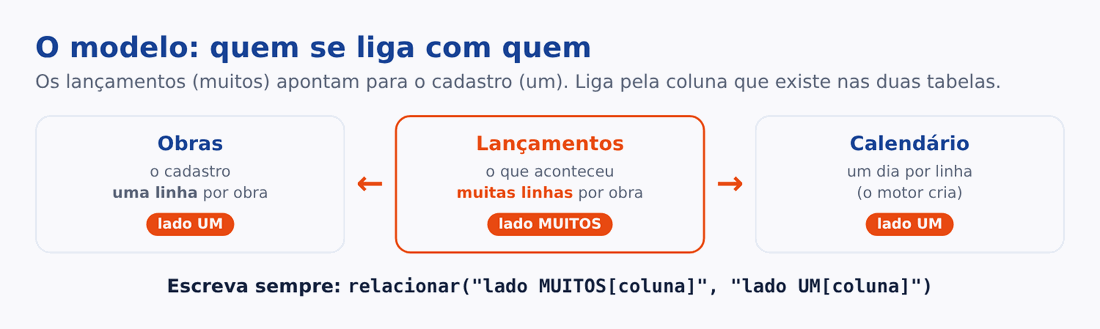

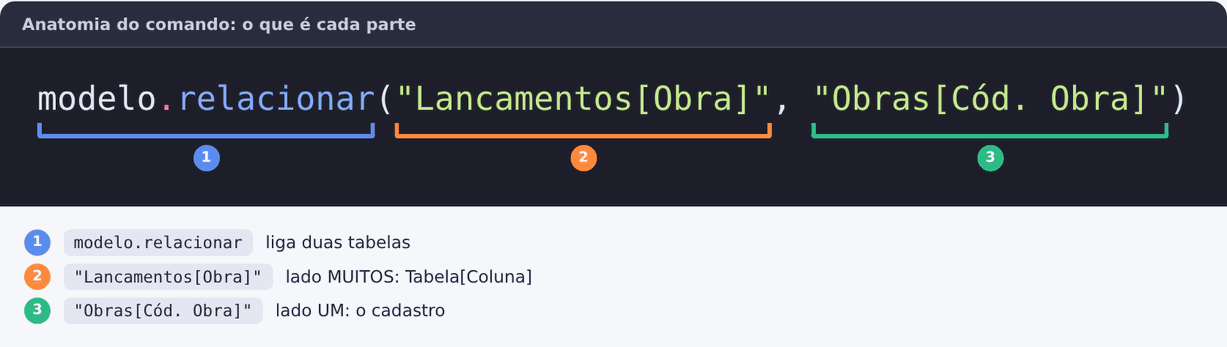

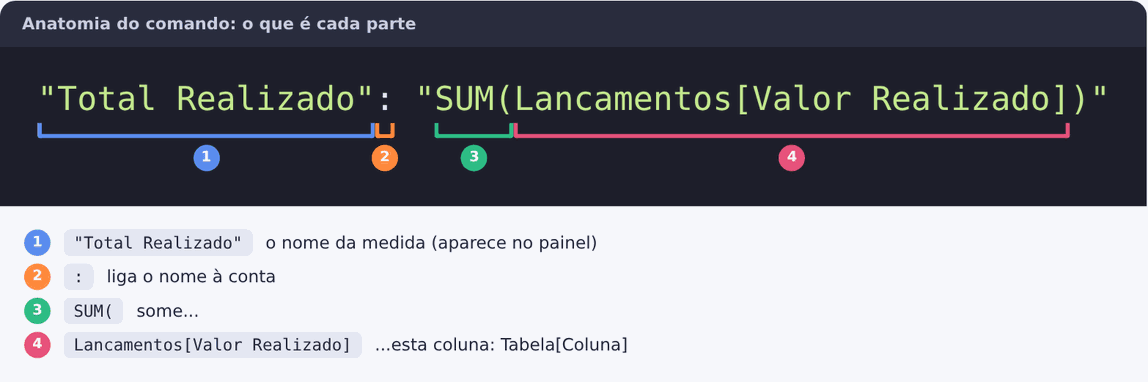

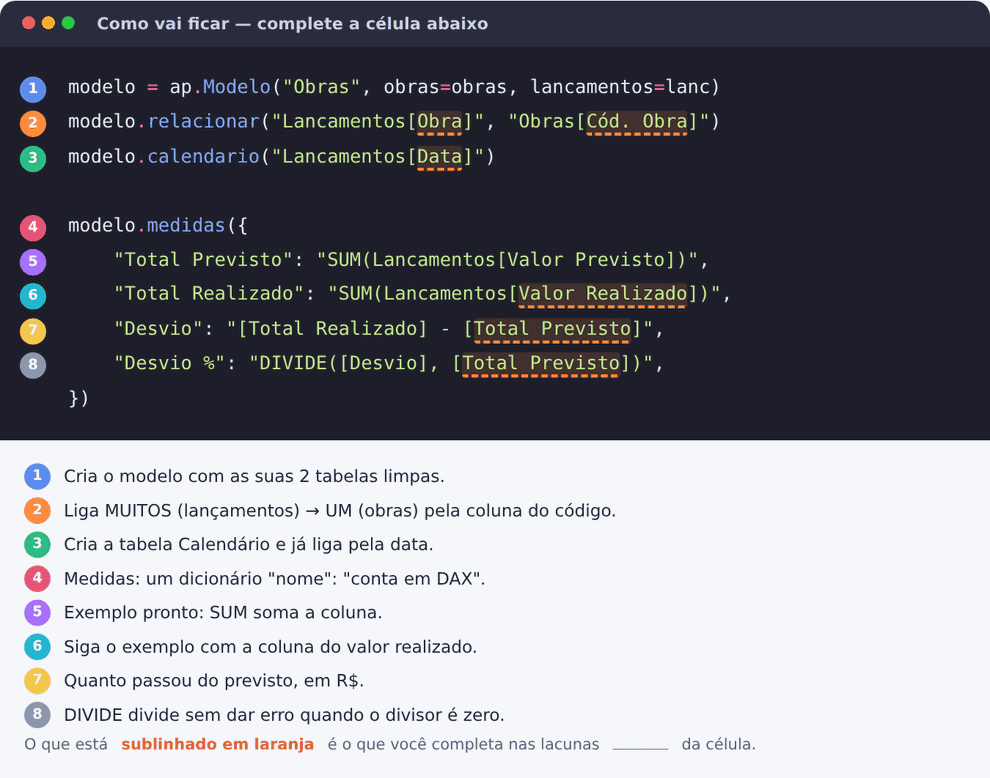

In [ ]:
# ✍️ Complete as lacunas olhando a imagem acima
modelo = ap.Modelo("Obras", obras=obras, lancamentos=lanc)
modelo.relacionar("Lancamentos[______]", "Obras[______]")
modelo.calendario("Lancamentos[______]")

modelo.medidas({
    "Total Previsto": "SUM(Lancamentos[Valor Previsto])",
    "Total Realizado": "SUM(Lancamentos[______])",
    "Desvio": "[Total Realizado] - [______]",
    "Desvio %": "DIVIDE([Desvio], [______])",
})

**👀 Resultado esperado**:
```text
📦 Modelo 'Obras' com as tabelas: Obras, Lancamentos
🔗 Lancamentos[Obra]  →  Obras[Cód. Obra]
📅 Calendario criado: 273 dias
🔗 Lancamentos[Data]  →  Calendario[Data]
📐 Total Previsto = SUM(Lancamentos[Valor Previsto])
📐 Total Realizado = SUM(Lancamentos[Valor Realizado])
📐 Desvio = [Total Realizado] - [Total Previsto]
📐 Desvio % = DIVIDE([Desvio], [Total Previsto])
```

### ✏️ SUA VEZ 1
Crie a medida **Qtd Obras**: quantas obras diferentes têm lançamento.

In [ ]:
modelo.medidas({"Qtd Obras": "______"})

**👀 Resultado esperado**:
```text
📐 Qtd Obras = DISTINCTCOUNT(Lancamentos[Obra])
```

💡 **Dica:** `DISTINCTCOUNT(Tabela[Coluna])` conta quantos valores **diferentes** a coluna tem. Ou pergunte ao tutor!

In [ ]:
tutor("Sugira 2 medidas DAX úteis para a gestão destas obras. Use só estas colunas:\n" + modelo.resumo())

**👀 Resultado esperado**:
```text
O tutor sugere 2 medidas. VOCÊ decide se fazem sentido antes de colocar no modelo.
```

---
# Parte 6 — Monte o painel e baixe o projeto
Cada linha vira um visual. **Coluna** se escreve `Tabela[Coluna]`; **medida**, só o nome.

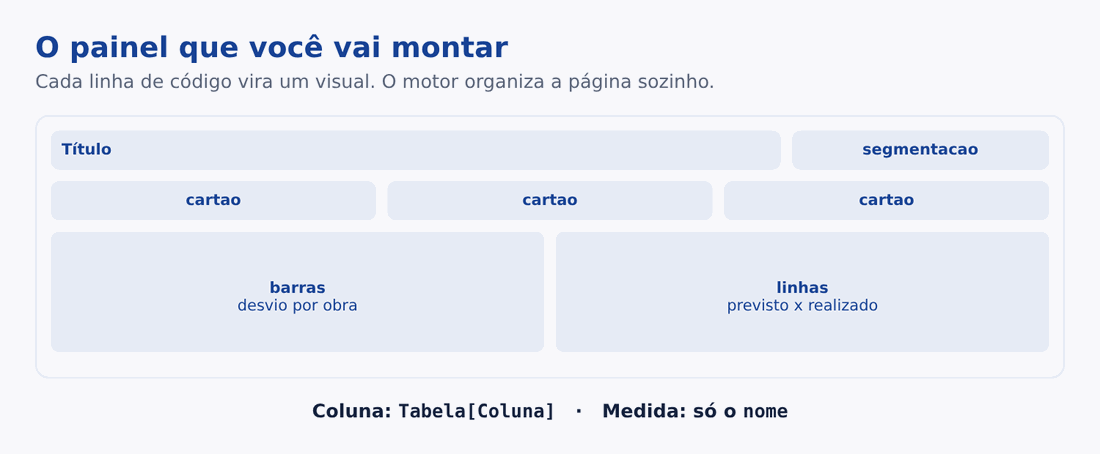

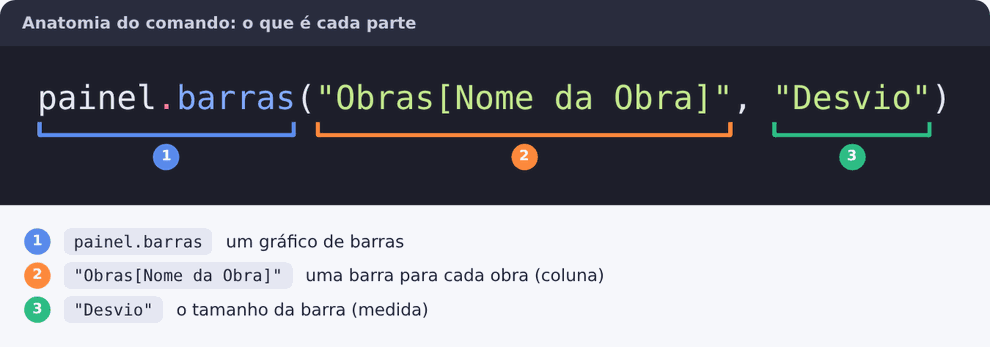

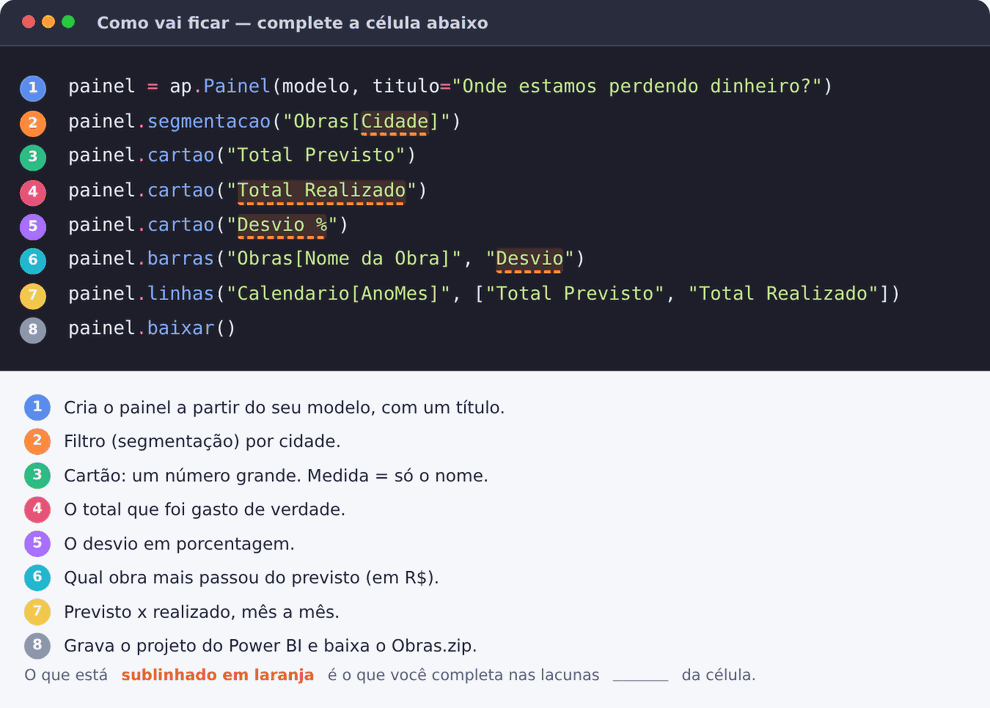

In [ ]:
# ✍️ Complete as lacunas olhando a imagem acima
painel = ap.Painel(modelo, titulo="Onde estamos perdendo dinheiro?")
painel.segmentacao("Obras[______]")
painel.cartao("Total Previsto")
painel.cartao("______")
painel.cartao("______")
painel.barras("Obras[Nome da Obra]", "______")
painel.linhas("Calendario[AnoMes]", ["Total Previsto", "Total Realizado"])
painel.baixar()

**👀 Resultado esperado**:
```text
✅ Modelo salvo em projeto/Obras.SemanticModel
✅ Painel salvo em projeto/Obras.Report com 6 visuais
📦 Obras.zip: extraia em qualquer pasta e abra projeto\Obras.pbip > Atualizar
(o download do Obras.zip começa sozinho)
```

### ✏️ SUA VEZ 2
Acrescente um gráfico de **colunas** com o **Total Realizado por Categoria** e baixe de novo.

In [ ]:
painel.colunas("Lancamentos[______]", "______")
painel.baixar()

**👀 Resultado esperado**:
```text
✅ Painel salvo em projeto/Obras.Report com 7 visuais
(um novo Obras.zip é baixado)
```

---
### 📊 Abrir no Power BI
1. Extraia o **Obras.zip** em qualquer pasta.
2. Abra **projeto › Obras.pbip** no Power BI Desktop.
3. Clique em **Atualizar** (Página Inicial).
4. Confira: quais obras estouraram o orçamento? Os números batem com o que o Python mostrou?

---
# Minhas conclusões ✍️
Dê **dois cliques** na célula abaixo e responda com suas palavras.

**1. Para que servem as REGRAS do tutor? O que mudou quando você tentou enganá-lo?**

*Escreva aqui...*

**2. Qual sujeira da planilha você achou mais perigosa para uma decisão da diretoria? Por quê?**

*Escreva aqui...*

**3. Quais obras precisam de atenção? O que você diria ao engenheiro?**

*Escreva aqui...*

### ✅ Antes de entregar, confira:
- [ ] Completei e executei todas as células, em ordem, sem 🟡 nem 🔴
- [ ] As 4 peças e as receitas `ler()` e `limpar()` deram ✅
- [ ] A limpeza **bateu** com o total do sistema
- [ ] Fiz as células **✏️ SUA VEZ** 1 e 2
- [ ] Abri o projeto no Power BI e cliquei em **Atualizar**
- [ ] Respondi às três perguntas e salvei uma cópia no meu Drive